In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
from xgboost import plot_importance
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor


# Load dataset


In [2]:
DATASET_PATH = '..\\' + "ml_dataset.csv"
data = pd.read_csv(DATASET_PATH)

data["delivery_day"] = pd.to_datetime(data["delivery_day"])
data = data.sort_values(["delivery_day", "hour"]).reset_index(drop=True)

data["target_price_next_day"] = data["price_value"].shift(-24)

data = data.dropna(subset=["target_price_next_day"])   


In [3]:
import sys

sys.path.append('..\\')

import feature_sets

In [4]:
feature_columns = feature_sets.FEATURE_SETS["full_set"]

In [5]:
print(feature_columns)

['hour', 'price_value', 'buy_volume_value', 'sell_volume_value', 'net_volume', 'flow_DK1_export', 'flow_DK1_import', 'flow_GER_export', 'flow_GER_import', 'flow_NL_export', 'flow_NL_import', 'flow_NO1_export', 'flow_NO1_import', 'flow_NO5_export', 'flow_NO5_import', 'capacity_GER', 'capacity_NL', 'capacity_NO1', 'capacity_NO5', 'util_GER', 'util_NL', 'util_NO1', 'util_NO5', 'capacity_missing_DK1', 'capacity_missing_GER', 'capacity_missing_NL', 'capacity_missing_NO1', 'capacity_missing_NO5', 'capacity_zero_DK1', 'capacity_zero_GER', 'capacity_zero_NL', 'capacity_zero_NO1', 'capacity_zero_NO5', 'price_DK1', 'price_NO1', 'price_NO5', 'price_NL', 'price_DE_LU', 'price_BE', 'price_FR', 'total_exports', 'total_imports', 'net_flow', 'day_of_week', 'month', 'day_of_year', 'day_sin', 'day_cos', 'year_sin', 'year_cos', 'price_lag_24', 'price_lag_168', 'price_DK1_lag24', 'price_NO1_lag24', 'price_NO5_lag24', 'price_DK1_lag168', 'price_NO1_lag168', 'price_NO5_lag168', 'Solar', 'Wind Onshore', 'Win

In [6]:
data.head()

,delivery_day,hour,price_value,buy_volume_value,sell_volume_value,net_volume,flow_DK1_export,flow_DK1_import,flow_GER_export,flow_GER_import,...,price_FR,Solar,Wind Onshore,Wind Offshore,Forecasted Generation,Forecasted Load,no2_reservoir_level_MWh,no1_reservoir_level_MWh,no5_reservoir_level_MWh,target_price_next_day
0,2024-10-01,0,3.31,4322.7,2079.3,2243.4,0.0,1425.0,0.0,1036.4,...,3.21,0.0,949.94,NaN,2245.80,3672.97,27435312.0,5566899.0,15268640.0,46.73
1,2024-10-01,1,0.08,4277.1,1849.0,2428.1,0.0,1425.0,0.0,1217.0,...,0.07,0.0,926.94,NaN,2024.80,3627.76,27435312.0,5566899.0,15268640.0,47.84
2,2024-10-01,2,0.05,4277.2,1938.7,2338.5,0.0,1425.0,0.0,1058.1,...,0.05,0.0,897.66,NaN,2169.23,3594.69,27435312.0,5566899.0,15268640.0,48.64
3,2024-10-01,3,0.02,4291.4,1928.2,2363.2,0.0,1425.0,0.0,1055.8,...,0.02,0.0,866.61,NaN,2134.06,3602.99,27435312.0,5566899.0,15268640.0,47.57
4,2024-10-01,4,8.00,4278.9,2149.6,2129.3,0.0,1425.0,0.0,562.0,...,0.09,0.0,837.23,NaN,2325.65,3617.94,27435312.0,5566899.0,15268640.0,47.23


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16990 entries, 0 to 16989
Data columns (total 68 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   delivery_day             16990 non-null  datetime64[us]
 1   hour                     16990 non-null  int64         
 2   price_value              16990 non-null  float64       
 3   buy_volume_value         16990 non-null  float64       
 4   sell_volume_value        16990 non-null  float64       
 5   net_volume               16990 non-null  float64       
 6   flow_DK1_export          16990 non-null  float64       
 7   flow_DK1_import          16990 non-null  float64       
 8   flow_GER_export          16990 non-null  float64       
 9   flow_GER_import          16990 non-null  float64       
 10  flow_NL_export           16990 non-null  float64       
 11  flow_NL_import           16990 non-null  float64       
 12  flow_NO1_export          16990 non-null  fl

In [8]:
data.describe()

,delivery_day,hour,price_value,buy_volume_value,sell_volume_value,net_volume,flow_DK1_export,flow_DK1_import,flow_GER_export,flow_GER_import,...,price_FR,Solar,Wind Onshore,Wind Offshore,Forecasted Generation,Forecasted Load,no2_reservoir_level_MWh,no1_reservoir_level_MWh,no5_reservoir_level_MWh,target_price_next_day
count,16990,16990.000000,16990.000000,16990.000000,16990.000000,16990.000000,16990.000000,16990.000000,16990.000000,16990.000000,...,16990.000000,16990.0,16990.000000,13581.000000,16990.000000,16990.000000,1.699000e+04,1.699000e+04,1.699000e+04,16990.000000
mean,2025-09-19 11:58:33.549146,11.501118,77.824862,11227.066098,14056.627351,-2829.561254,874.516286,228.480547,778.670436,175.175650,...,106.445257,0.0,504.895101,1.433042,5988.140771,4186.119065,1.924300e+07,3.631537e+06,9.993176e+06,77.975960
min,2024-10-01 00:00:00,0.000000,-31.490000,2785.000000,1386.800000,-23456.600000,0.000000,0.000000,0.000000,0.000000,...,-496.862500,0.0,0.000000,0.000000,699.797000,2609.597500,9.402154e+06,9.067830e+05,2.491772e+06,-31.490000
25%,2025-03-26 06:00:00,6.000000,48.581250,4480.950000,5860.125000,-4863.500000,0.000000,0.000000,50.350000,0.000000,...,62.270000,0.0,158.386750,0.000000,4270.303187,3577.160000,1.640055e+07,2.425247e+06,6.733015e+06,48.704375
50%,2025-09-19 12:00:00,12.000000,72.223750,5665.500000,8862.950000,-2058.550000,1010.600000,0.000000,928.000000,0.000000,...,113.873750,0.0,410.739375,0.800000,6195.622375,3983.489250,1.920734e+07,4.126965e+06,1.040615e+07,72.345000
75%,2026-03-15 00:00:00,17.750000,103.010000,18377.700000,22498.275000,334.375000,1631.300000,69.225000,1310.000000,0.000000,...,158.967500,0.0,833.343875,2.900000,7695.403000,4746.339562,2.287084e+07,4.579346e+06,1.368730e+07,103.220625
max,2026-09-08 00:00:00,23.000000,898.250000,30206.800000,44158.100000,13992.100000,1631.300000,1680.000000,1444.000000,1399.200000,...,473.280000,0.0,1333.677500,5.600000,10742.940000,6554.733837,2.926449e+07,5.753295e+06,1.633139e+07,898.250000
std,NaN,6.922030,42.081283,7108.785952,10574.713050,6026.438569,684.697423,479.934104,562.274071,396.186707,...,60.474080,0.0,388.242382,1.561225,2269.652615,784.594725,5.035536e+06,1.369505e+06,3.880288e+06,42.109072


## Dataset plots

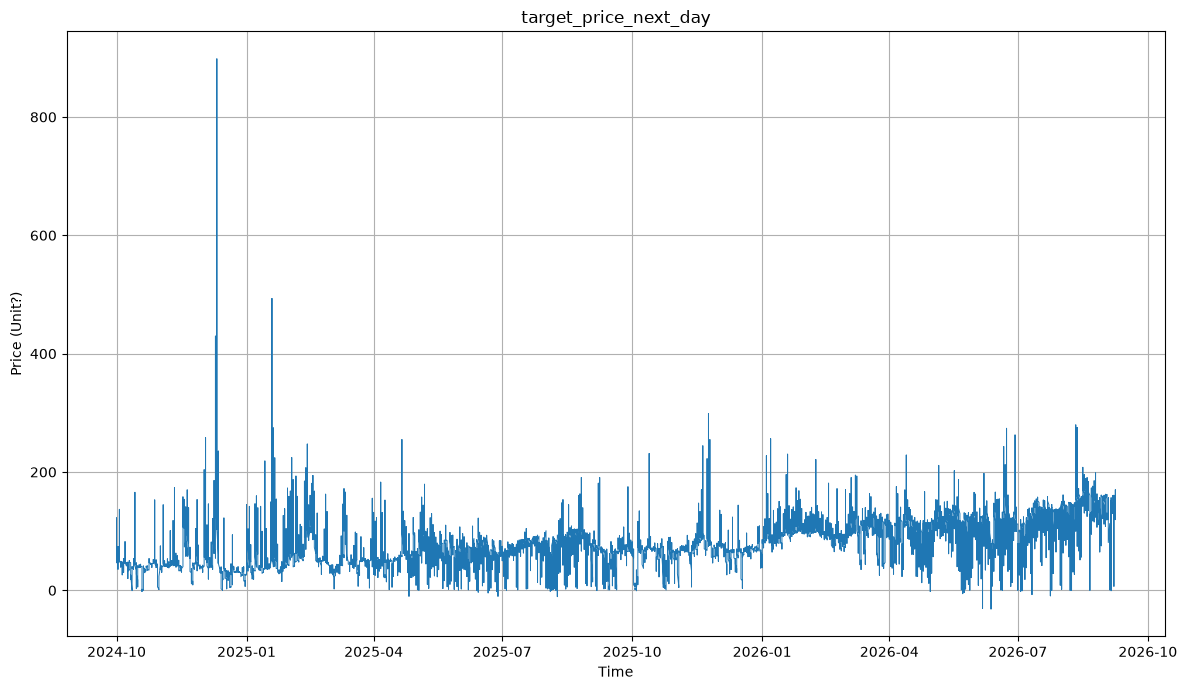

In [9]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["target_price_next_day"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("Price (Unit?)")
plt.title("target_price_next_day")
plt.grid(True)
plt.tight_layout()
plt.show()

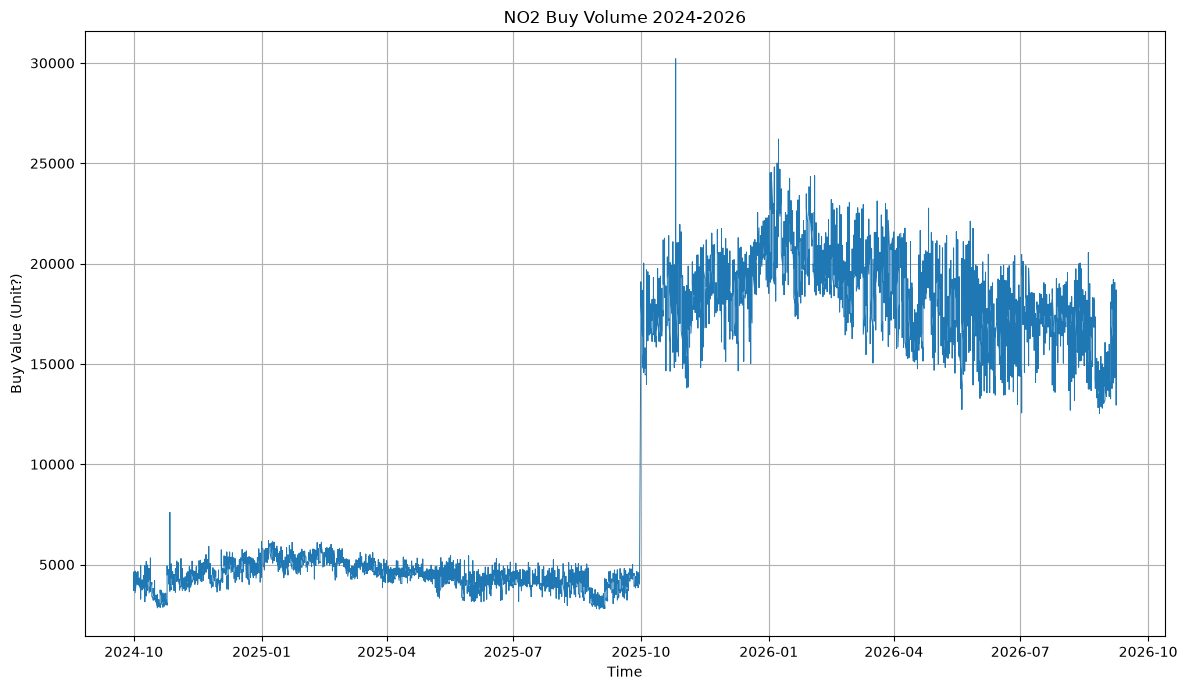

In [10]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["buy_volume_value"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("Buy Value (Unit?)")
plt.title("NO2 Buy Volume 2024-2026")
plt.grid(True)
plt.tight_layout()
plt.show()

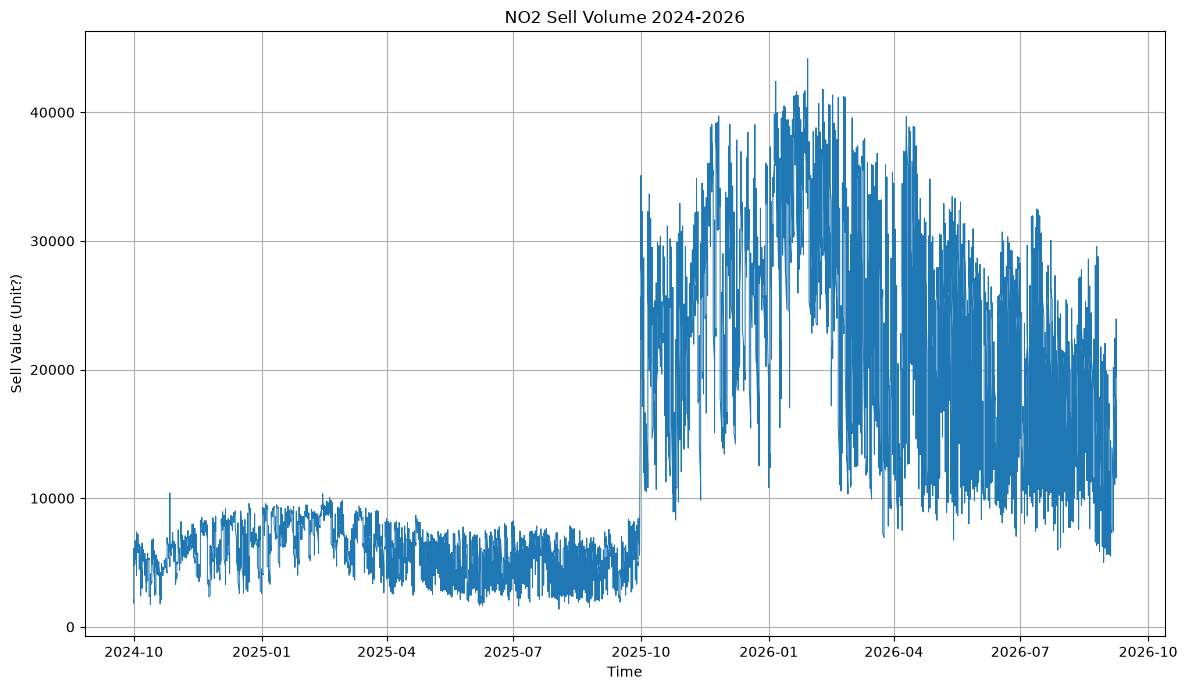

In [11]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["sell_volume_value"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("Sell Value (Unit?)")
plt.title("NO2 Sell Volume 2024-2026")
plt.grid(True)
plt.tight_layout()
plt.show()

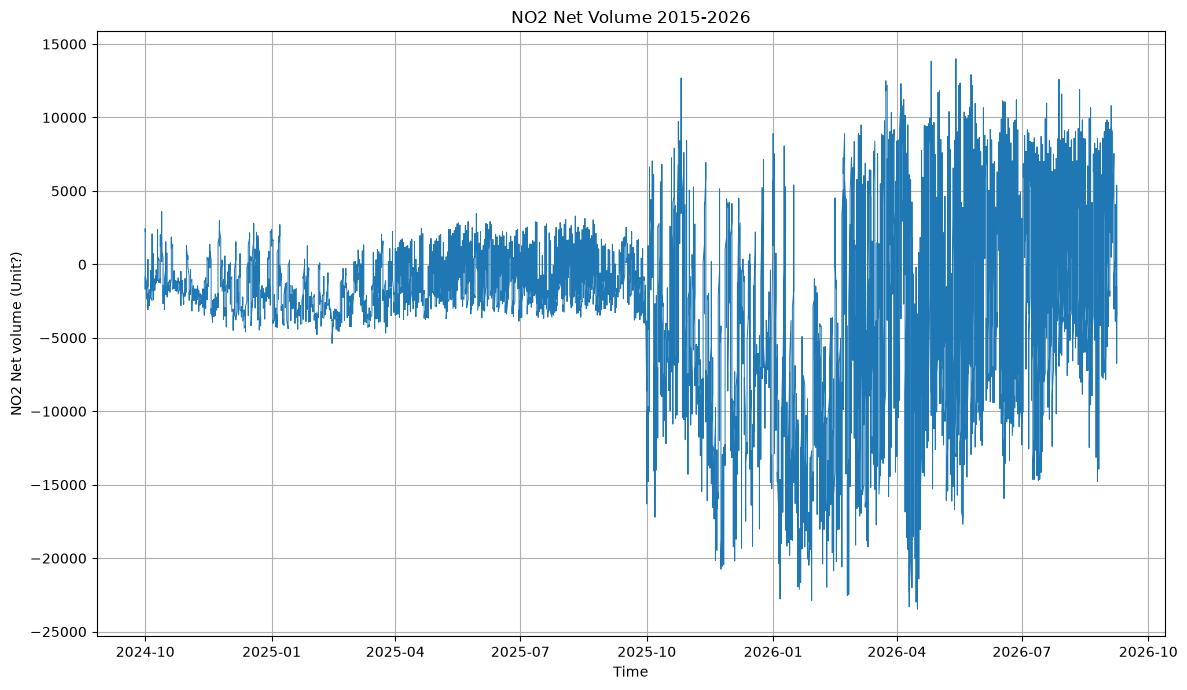

In [12]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["net_volume"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("NO2 Net volume (Unit?)")
plt.title("NO2 Net Volume 2015-2026")
plt.grid(True)
plt.tight_layout()
plt.show()

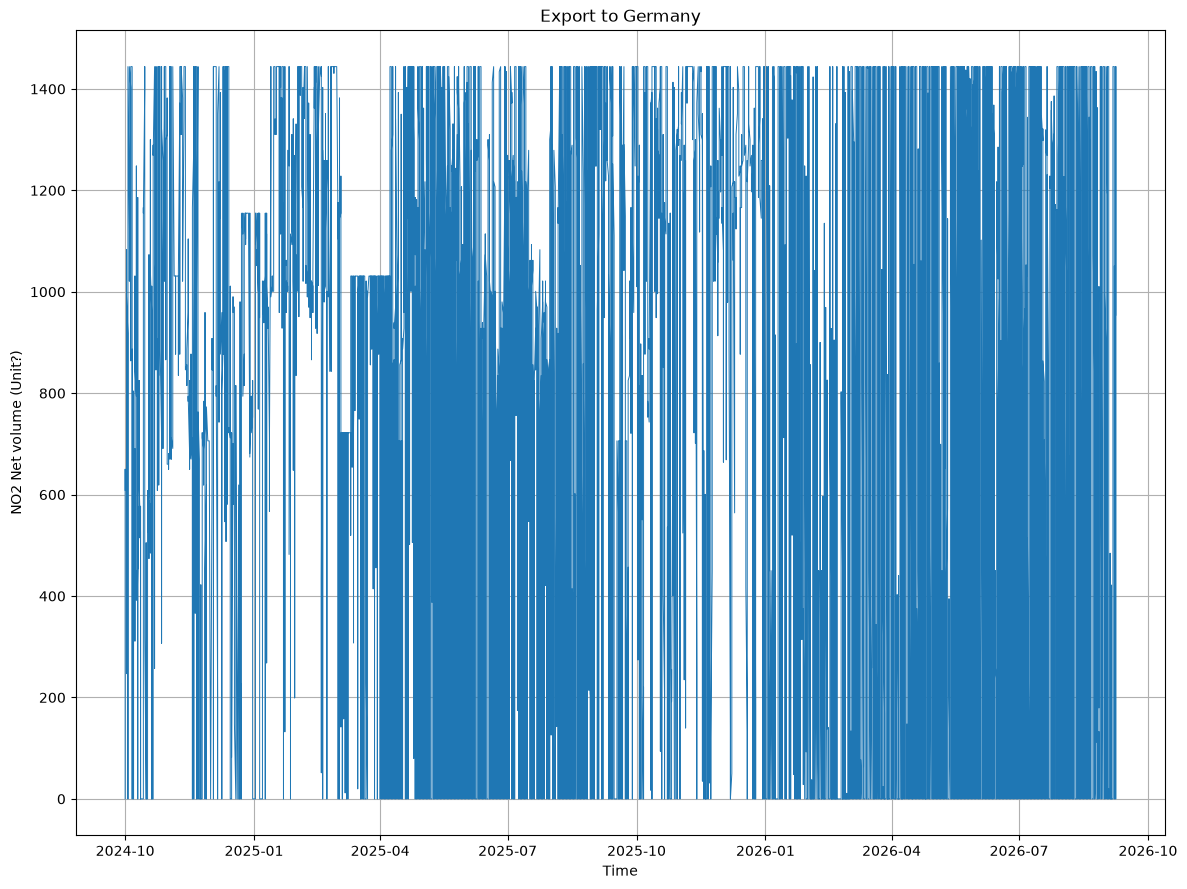

In [14]:
plt.figure(figsize=(12, 9))
plt.plot(
    data["delivery_day"], data['flow_GER_export'], 
    linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("NO2 Net volume (Unit?)")
plt.title("Export to Germany")
plt.grid(True)
plt.tight_layout()
plt.show()

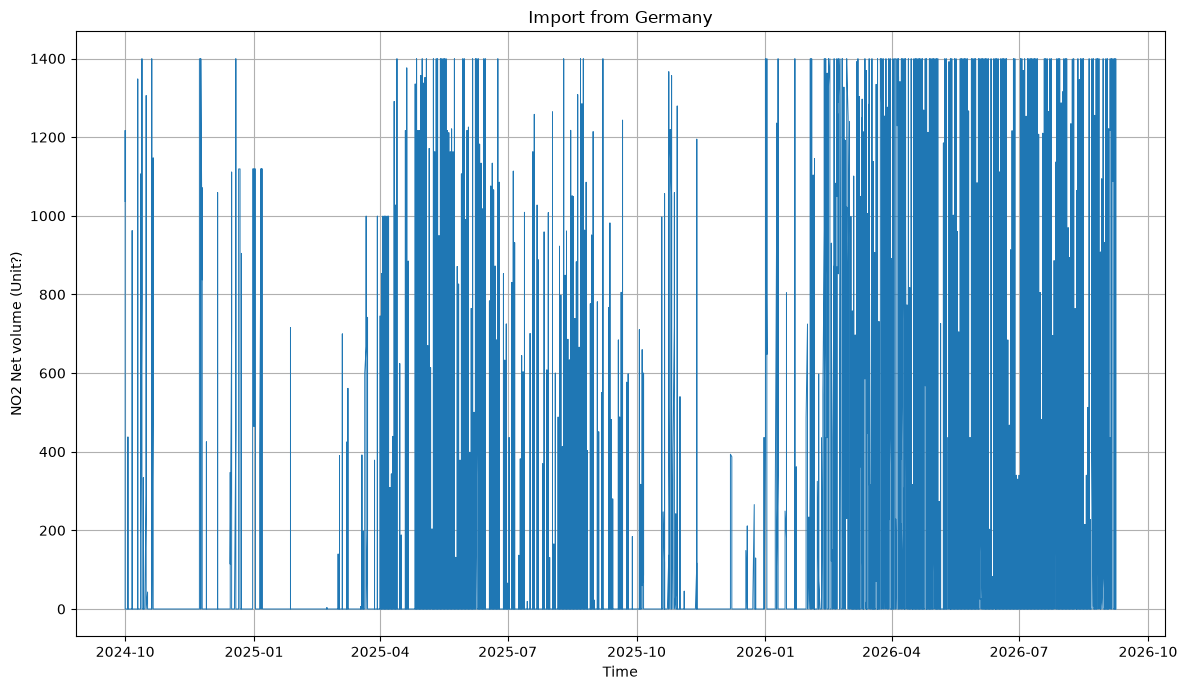

In [15]:
plt.figure(figsize=(12, 7))
plt.plot(
    data["delivery_day"], data['flow_GER_import'],
    linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("NO2 Net volume (Unit?)")
plt.title("Import from Germany")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
data.columns

Index(['delivery_day', 'hour', 'price_value', 'buy_volume_value',
       'sell_volume_value', 'net_volume', 'flow_DK1_export', 'flow_DK1_import',
       'flow_GER_export', 'flow_GER_import', 'flow_NL_export',
       'flow_NL_import', 'flow_NO1_export', 'flow_NO1_import',
       'flow_NO5_export', 'flow_NO5_import', 'capacity_GER', 'capacity_NL',
       'capacity_NO1', 'capacity_NO5', 'util_GER', 'util_NL', 'util_NO1',
       'util_NO5', 'capacity_missing_DK1', 'capacity_missing_GER',
       'capacity_missing_NL', 'capacity_missing_NO1', 'capacity_missing_NO5',
       'capacity_zero_DK1', 'capacity_zero_GER', 'capacity_zero_NL',
       'capacity_zero_NO1', 'capacity_zero_NO5', 'price_DK1', 'price_NO1',
       'price_NO5', 'total_exports', 'total_imports', 'net_flow',
       'day_of_week', 'month', 'day_of_year', 'day_sin', 'day_cos', 'year_sin',
       'year_cos', 'price_lag_24', 'price_lag_168', 'price_DK1_lag24',
       'price_NO1_lag24', 'price_NO5_lag24', 'price_DK1_lag168',
       

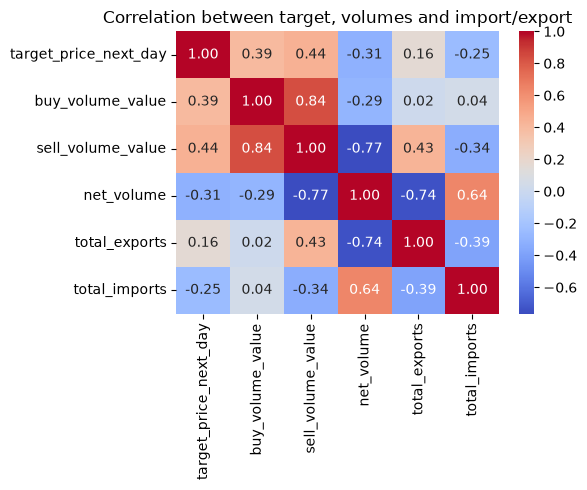

In [18]:
num_cols = [
    'target_price_next_day',
    'buy_volume_value',
    'sell_volume_value',
    'net_volume',
    'total_exports', 
    'total_imports',
]

corr = data[num_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between target, volumes and import/export")
plt.tight_layout()
plt.show()

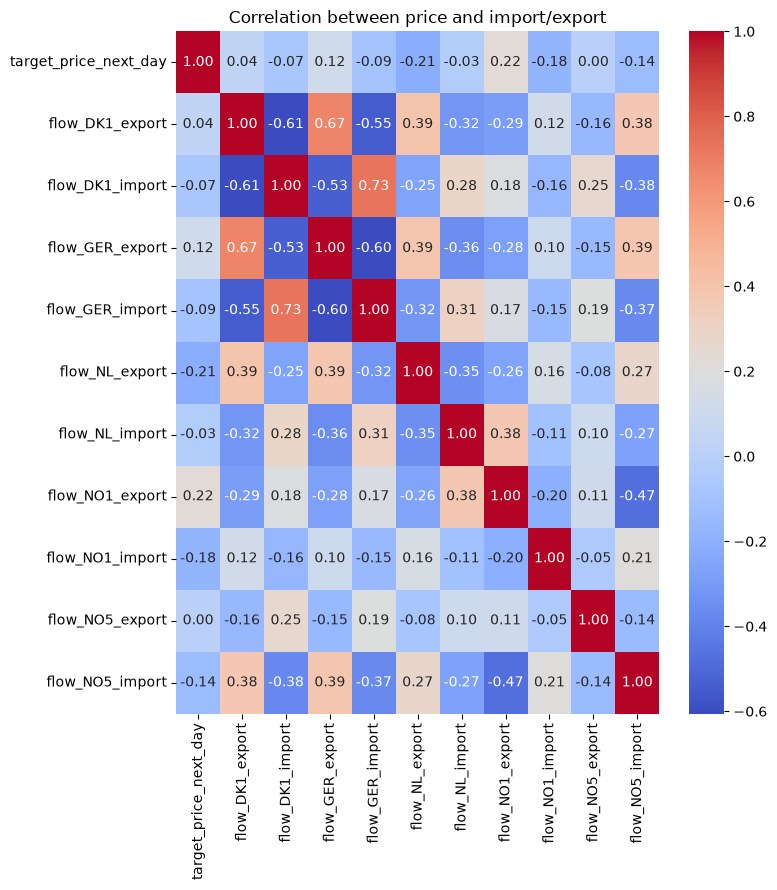

In [19]:
num_cols = [
    'target_price_next_day',
    'flow_DK1_export', 
    'flow_DK1_import',
    'flow_GER_export', 
    'flow_GER_import', 
    'flow_NL_export',
    'flow_NL_import', 
    'flow_NO1_export',
    'flow_NO1_import',
    'flow_NO5_export',
    'flow_NO5_import'
]

corr = data[num_cols].corr()

plt.figure(figsize=(8, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between price and import/export")
plt.tight_layout()
plt.show()

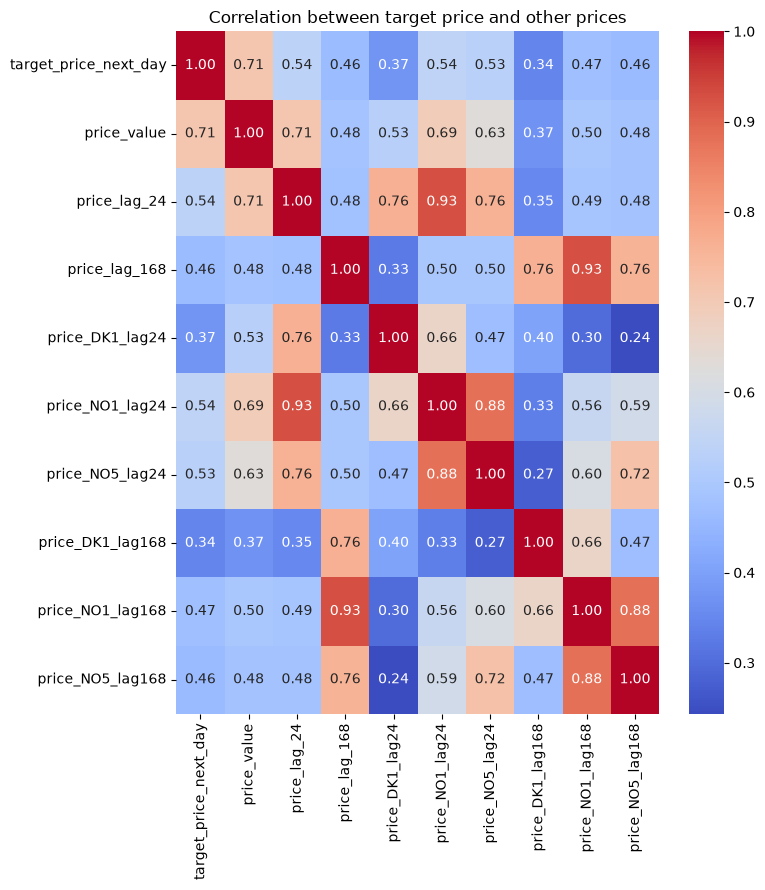

In [22]:
num_cols = [
    'target_price_next_day',
    'price_value',
    'price_lag_24', 
    'price_lag_168', 
    'price_DK1_lag24',
    'price_NO1_lag24', 
    'price_NO5_lag24', 
    'price_DK1_lag168',
    'price_NO1_lag168', 
    'price_NO5_lag168'
]

corr = data[num_cols].corr()

plt.figure(figsize=(8, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between target price and other prices")
plt.tight_layout()
plt.show()

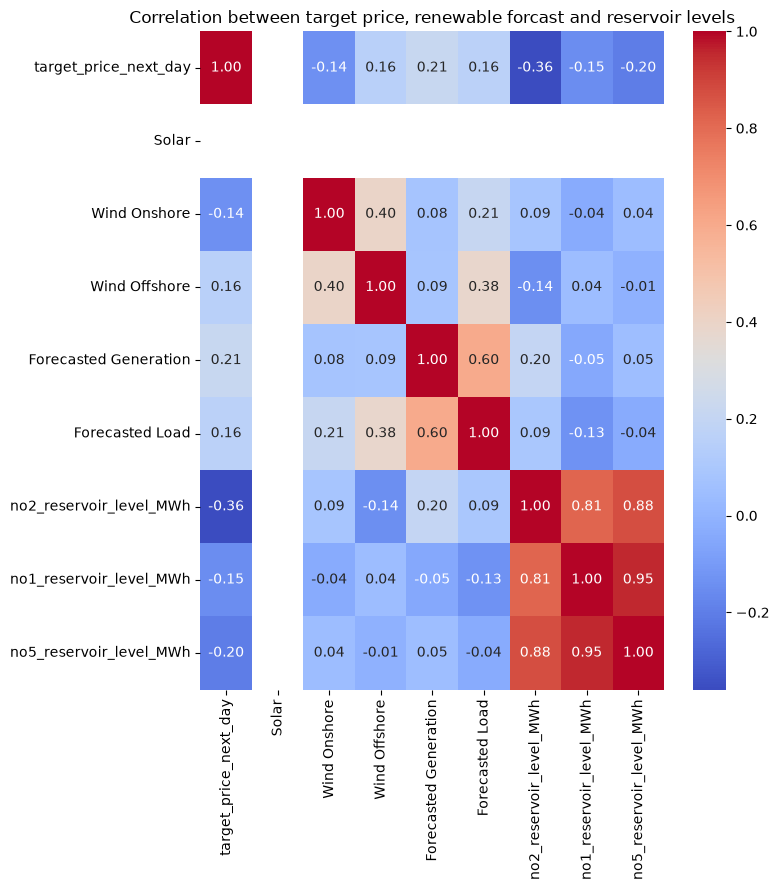

In [25]:
num_cols = [
    'target_price_next_day',
    'Solar', 
    'Wind Onshore', 
    'Wind Offshore',
    'Forecasted Generation', 
    'Forecasted Load', 
    'no2_reservoir_level_MWh',
    'no1_reservoir_level_MWh',
    'no5_reservoir_level_MWh'
]

corr = data[num_cols].corr()

plt.figure(figsize=(8, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between target price, renewable forcast and reservoir levels")
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

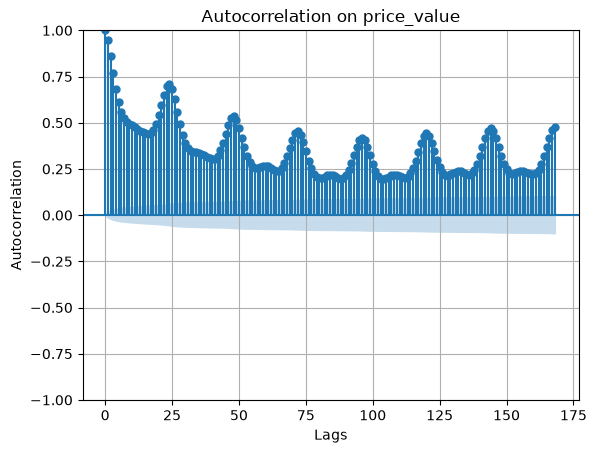

In [23]:
from statsmodels.graphics.tsaplots import plot_acf
plt.figure(figsize=(12,5))
plot_acf(data['target_price_next_day'], lags=168)
plt.xlabel('Lags')
plt.ylabel('Autocorrelation')
plt.title('Autocorrelation on price_value')
plt.grid(True)
plt.show()

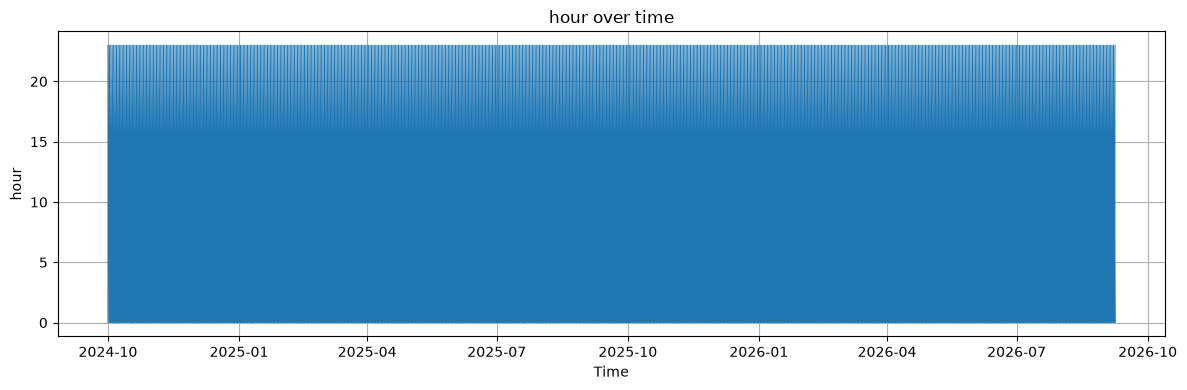

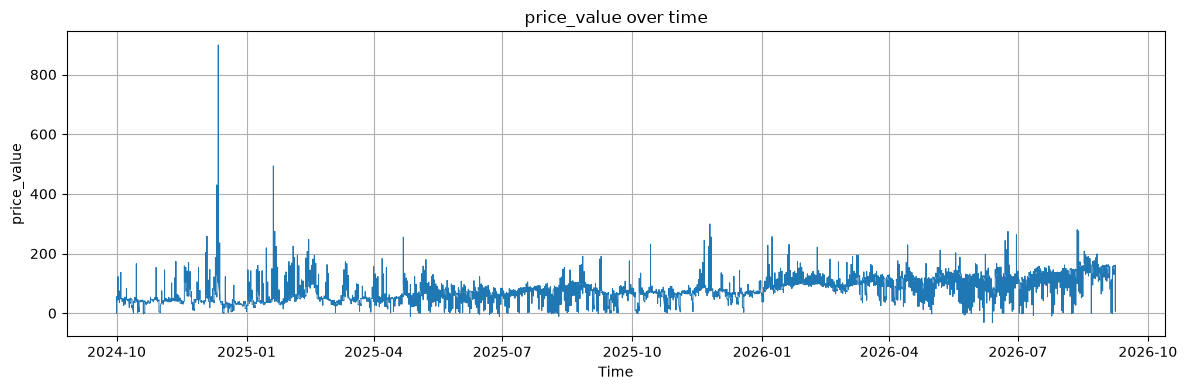

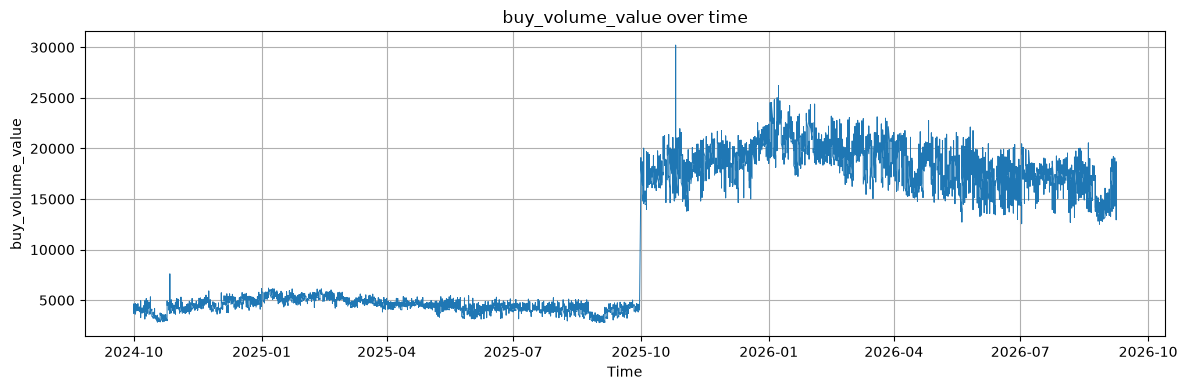

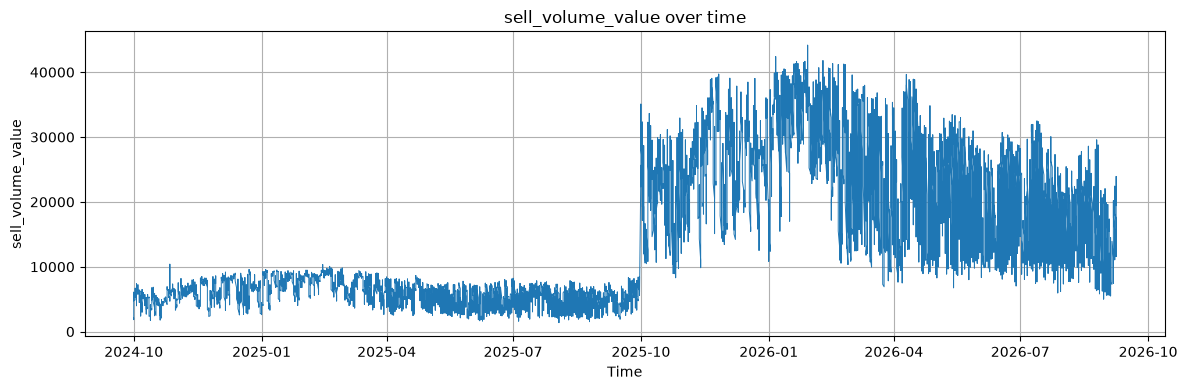

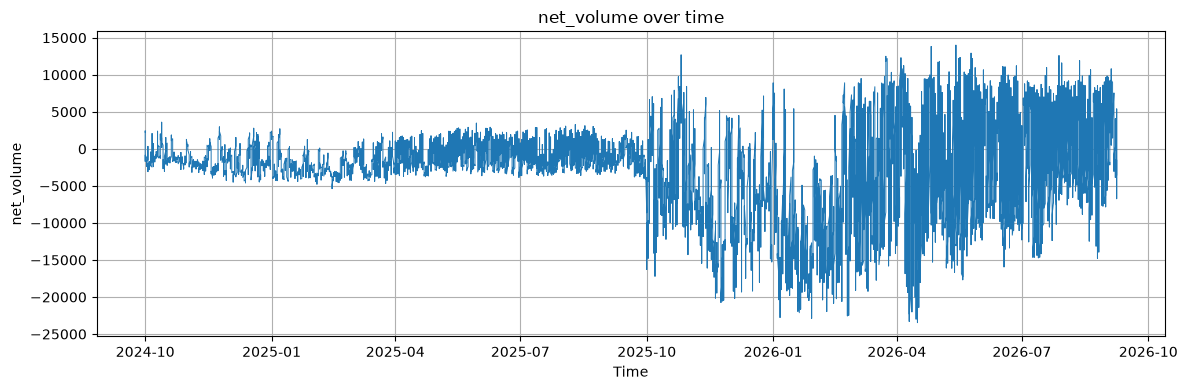

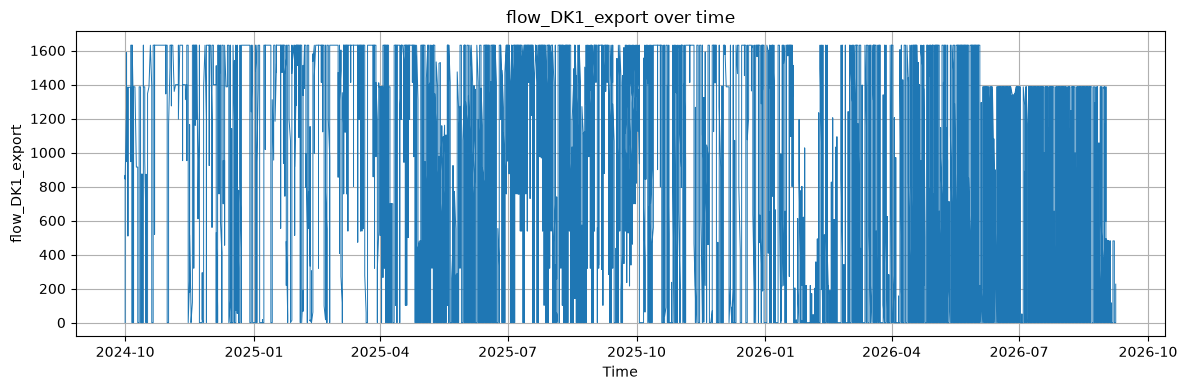

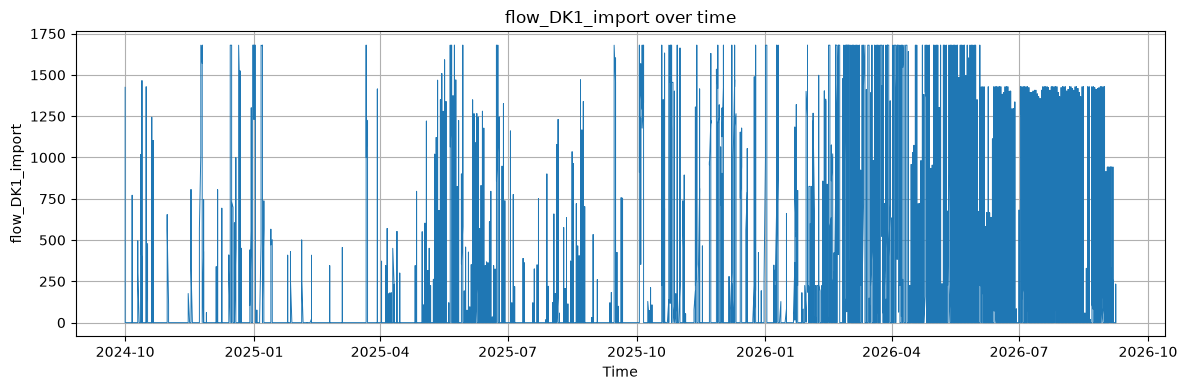

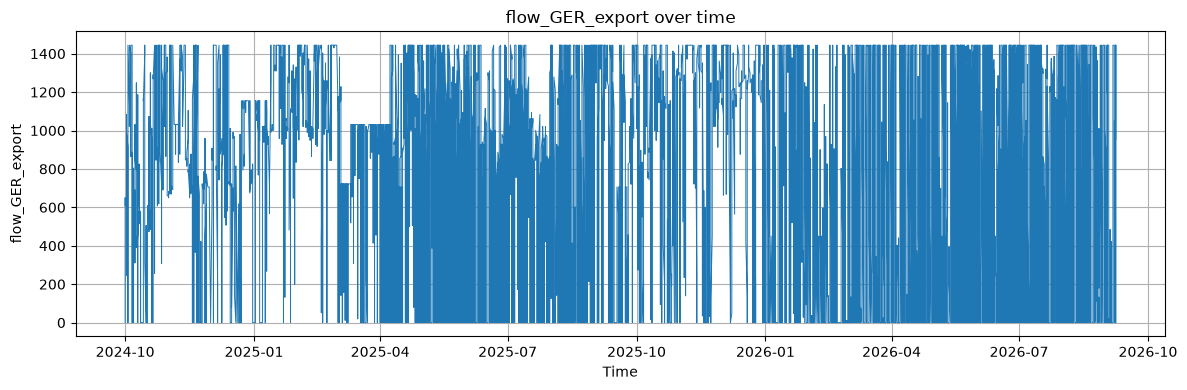

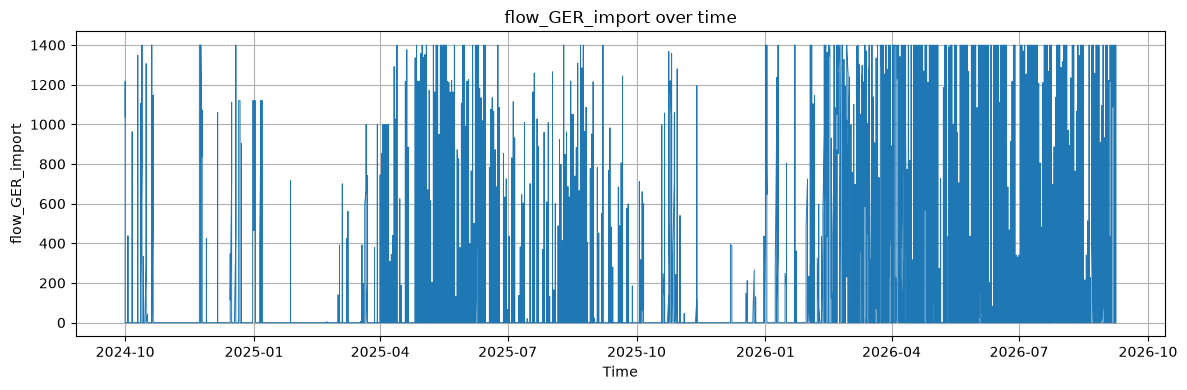

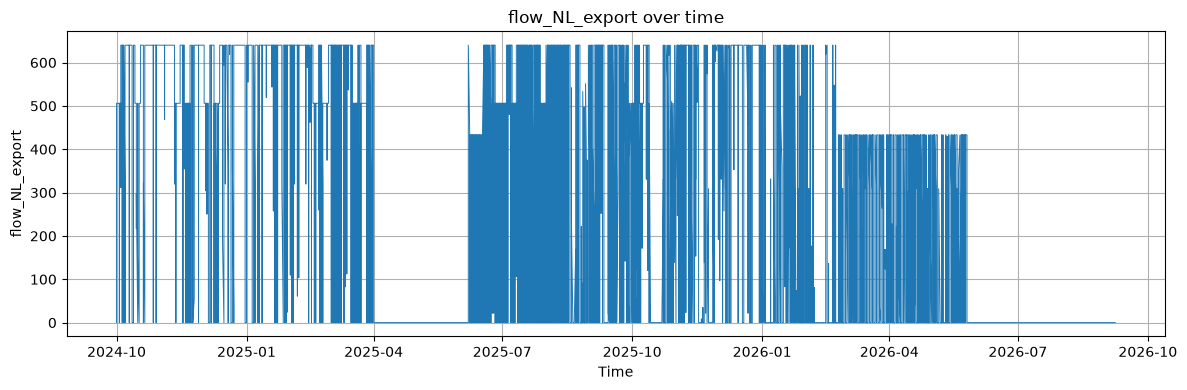

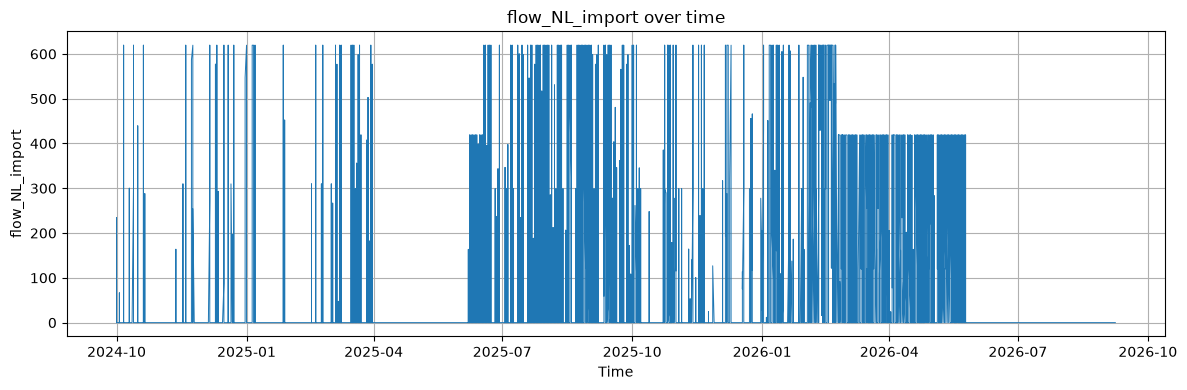

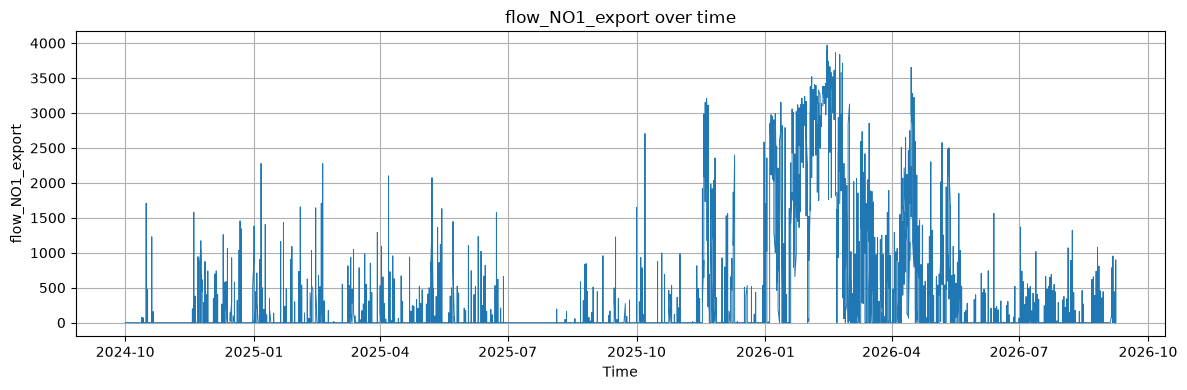

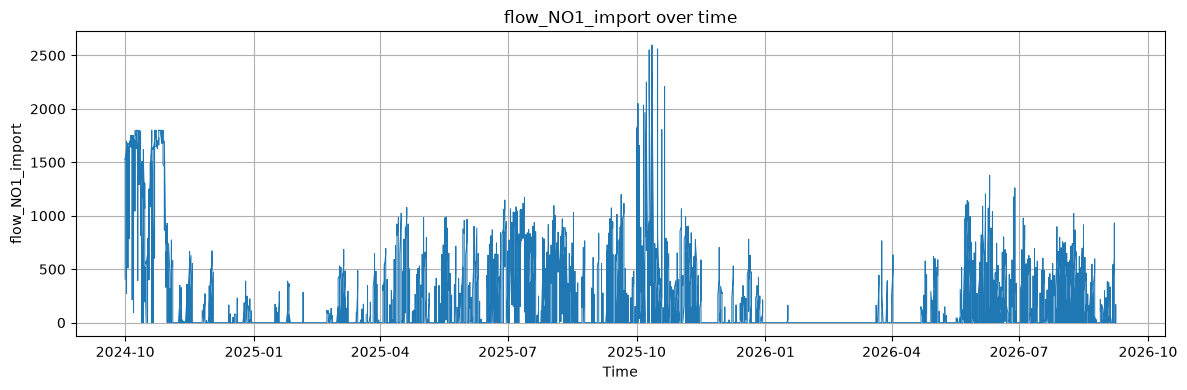

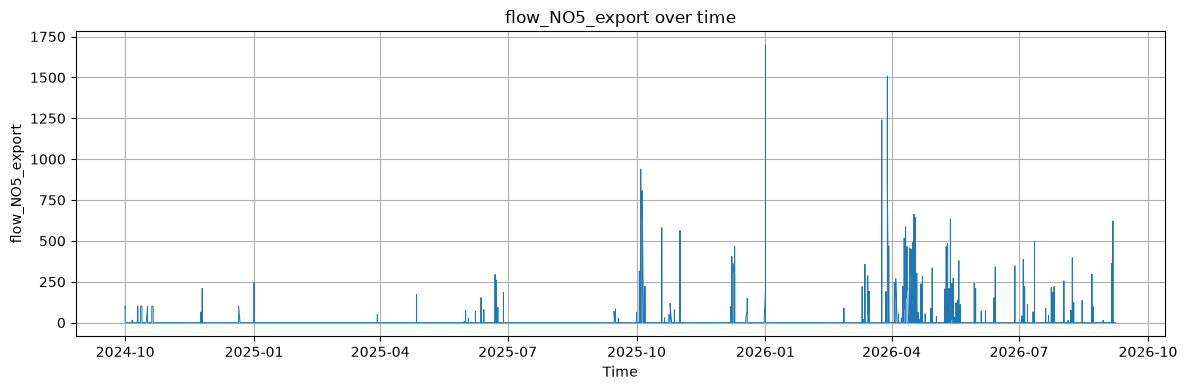

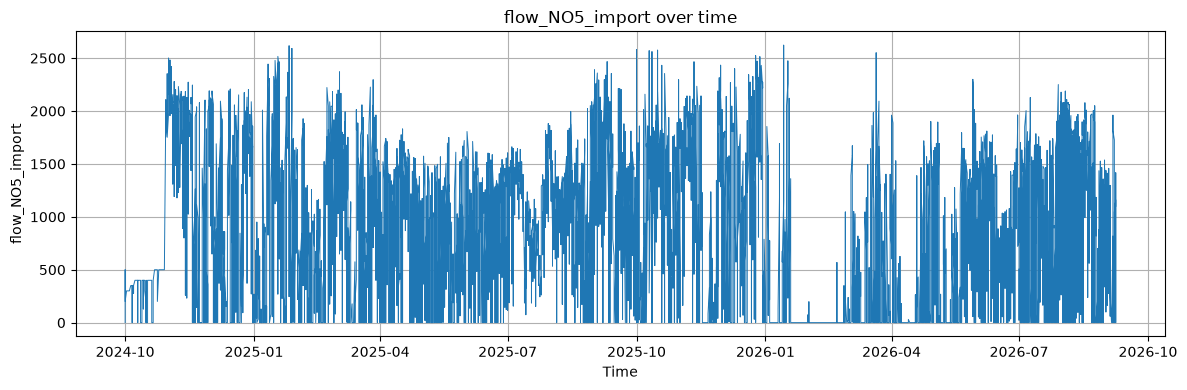

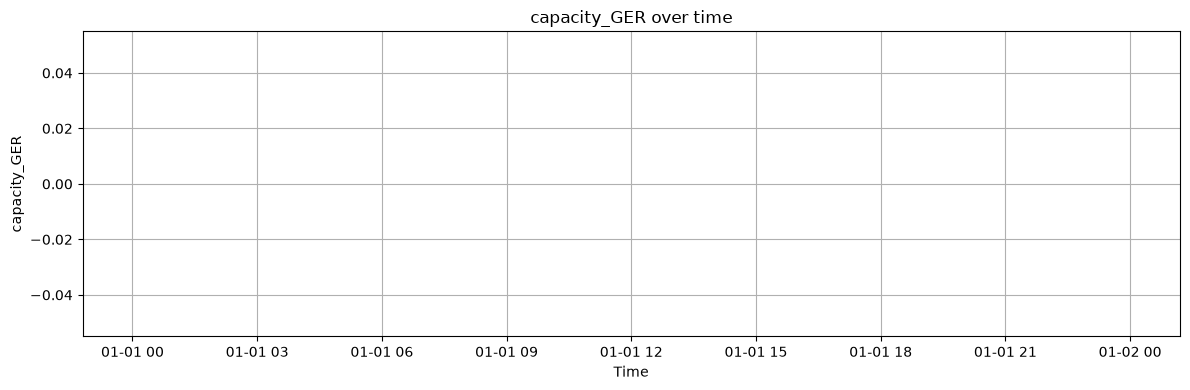

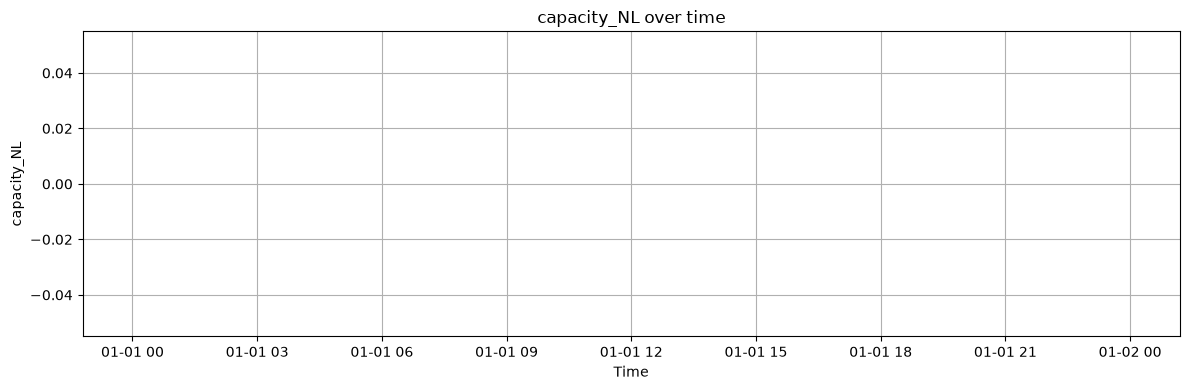

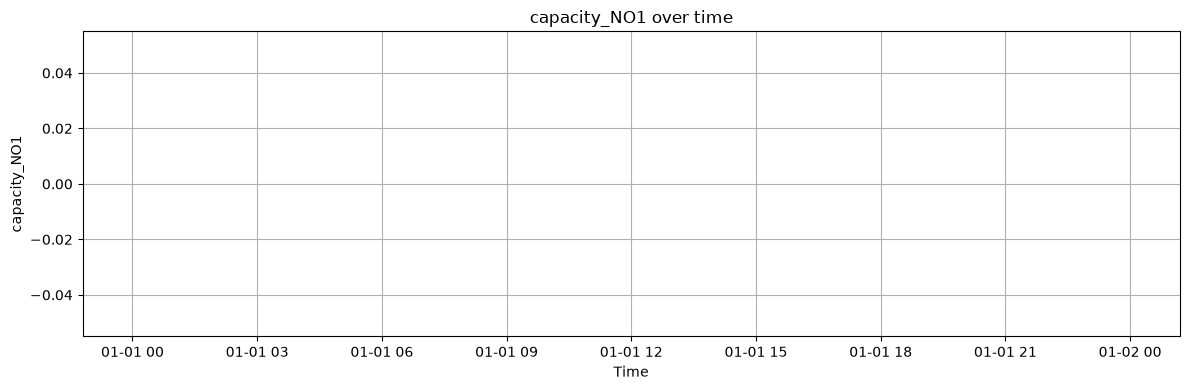

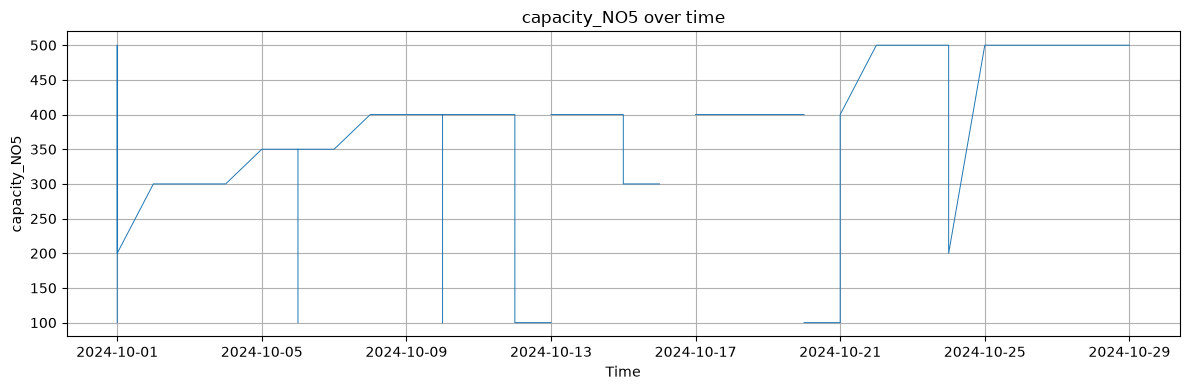

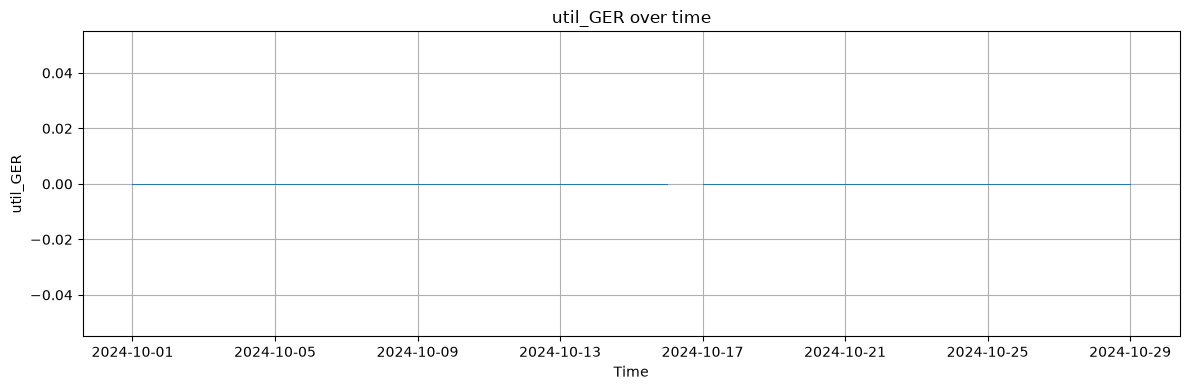

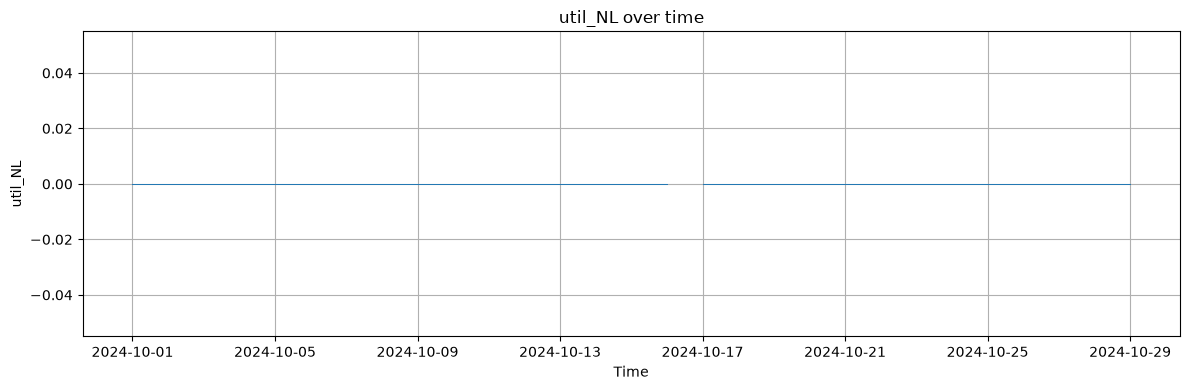

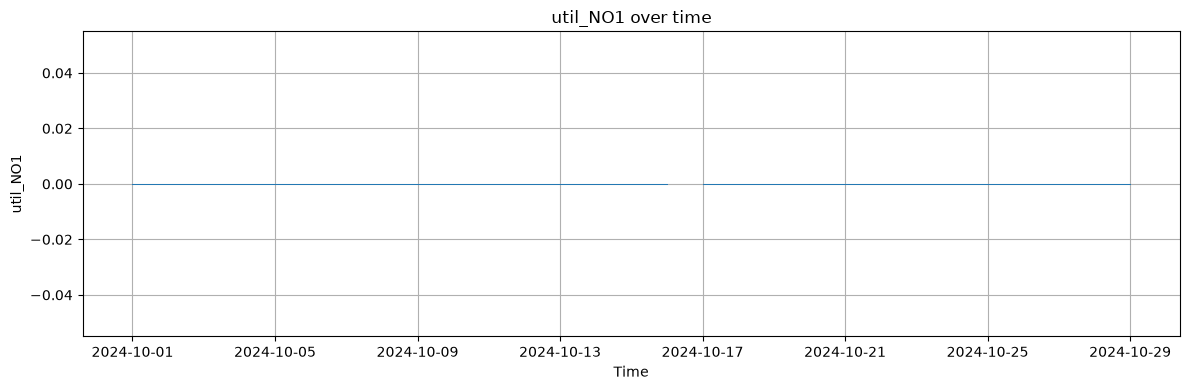

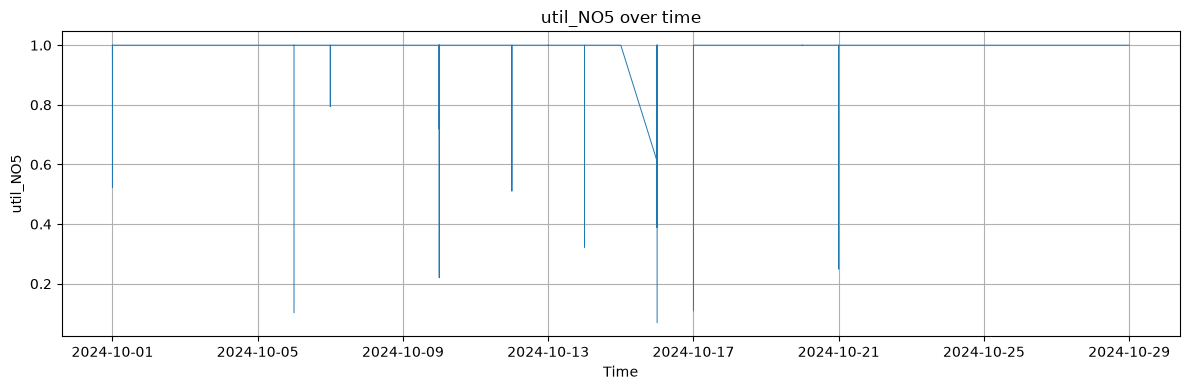

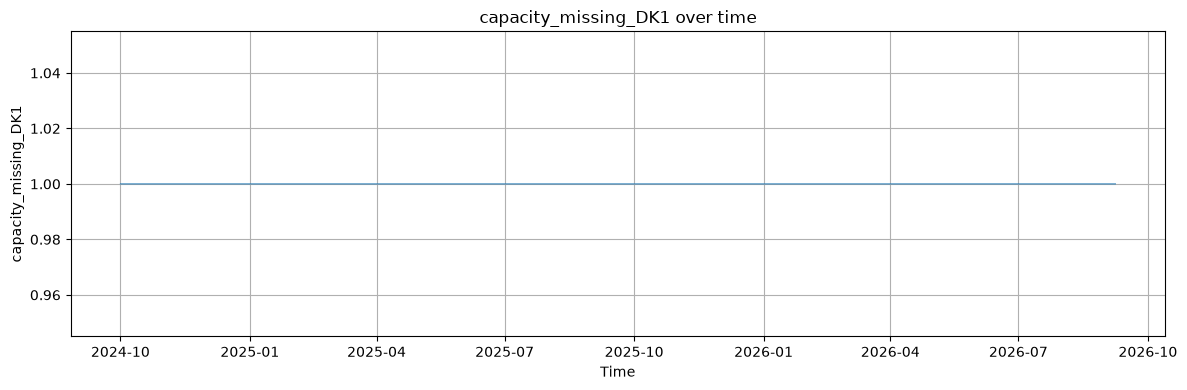

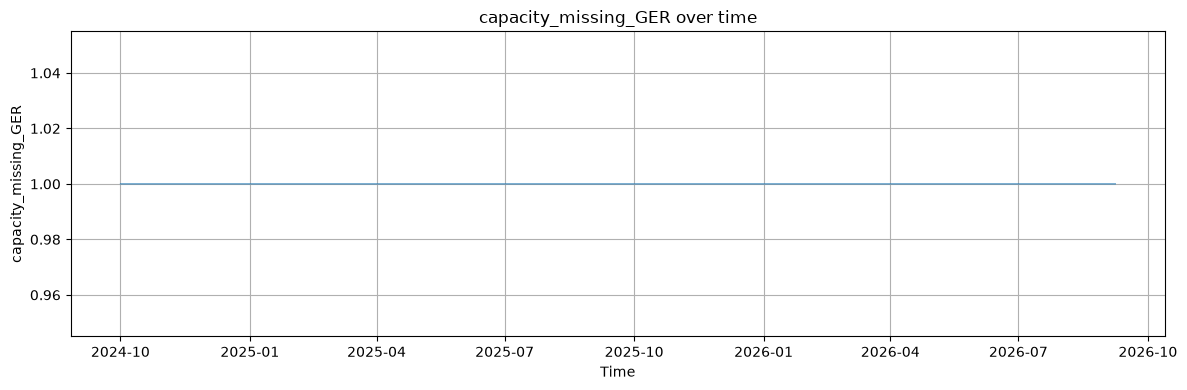

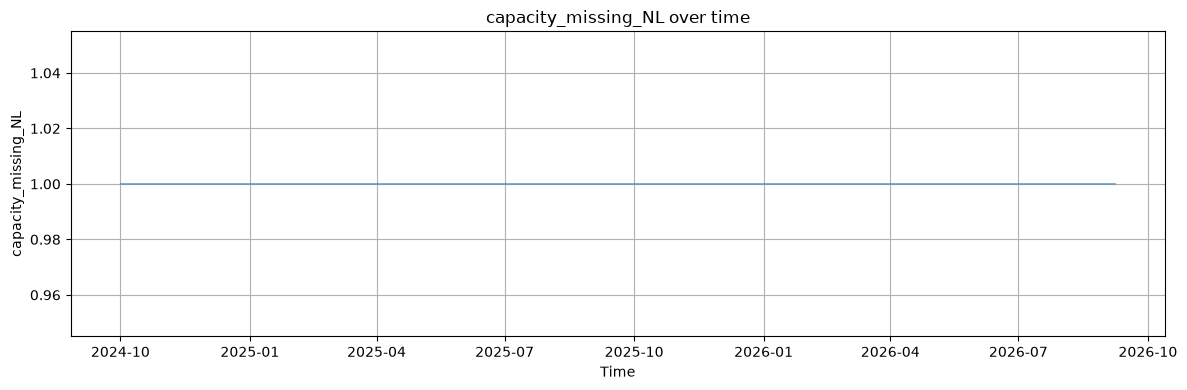

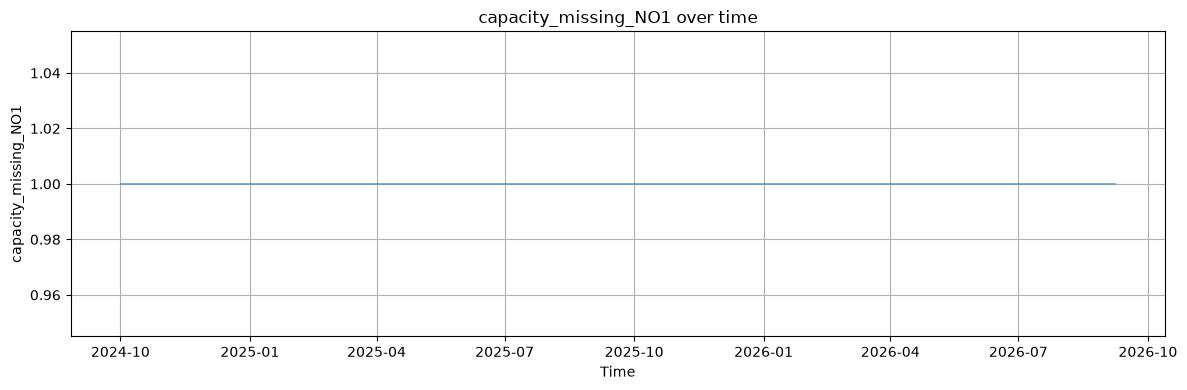

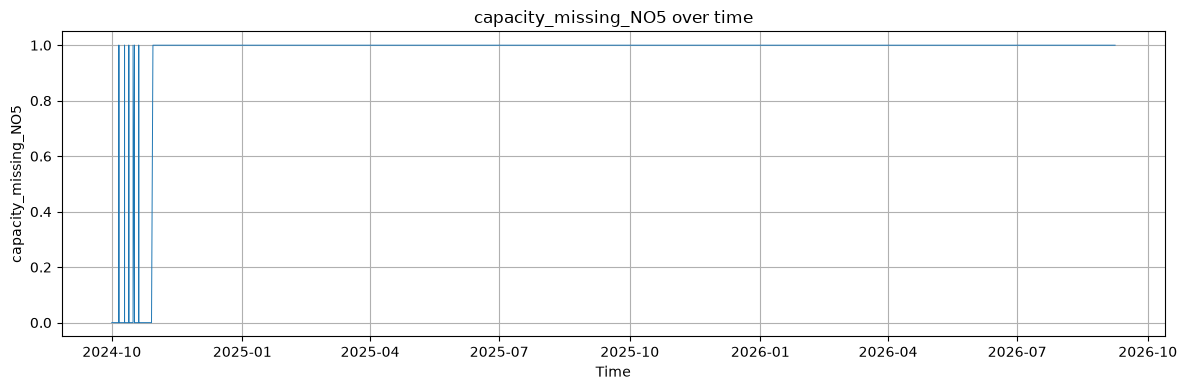

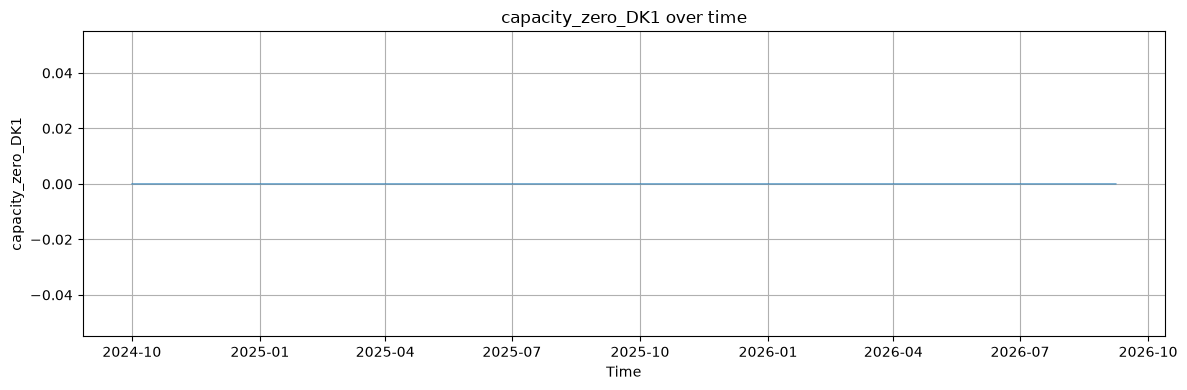

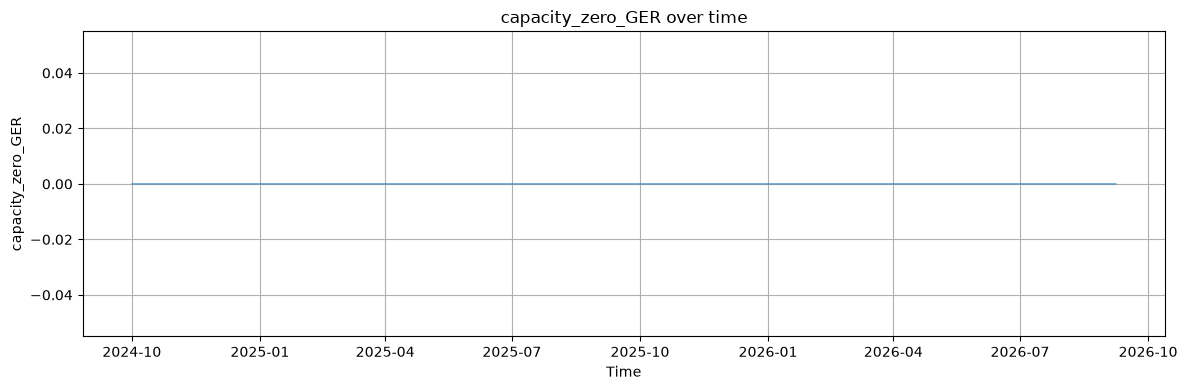

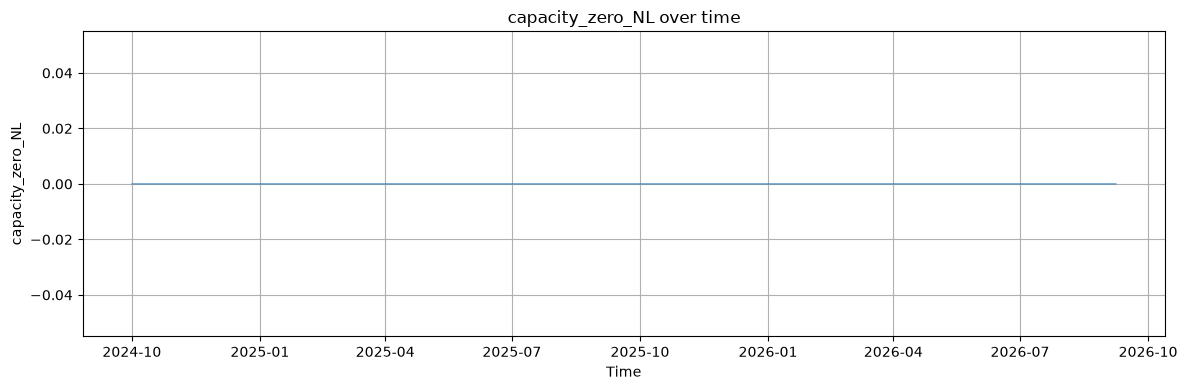

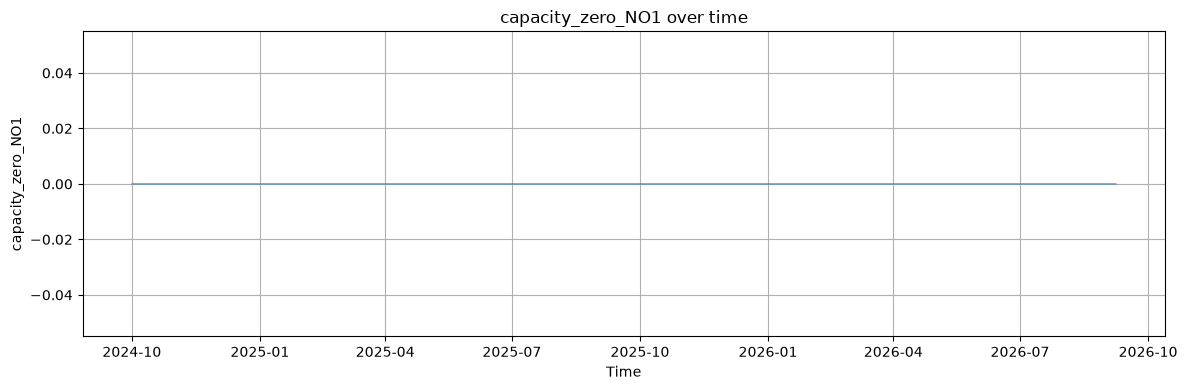

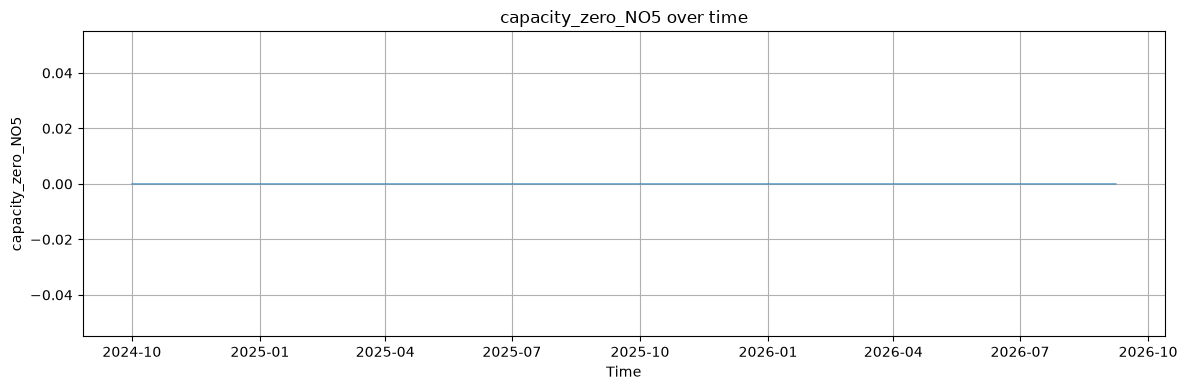

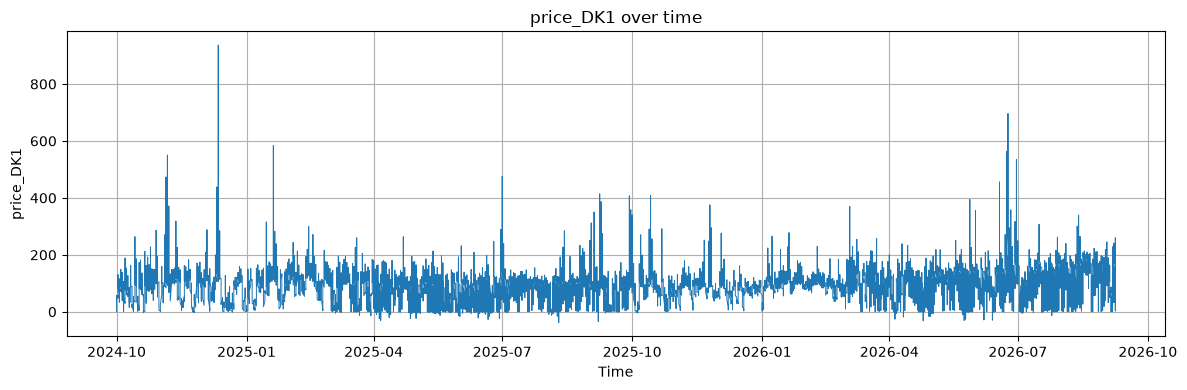

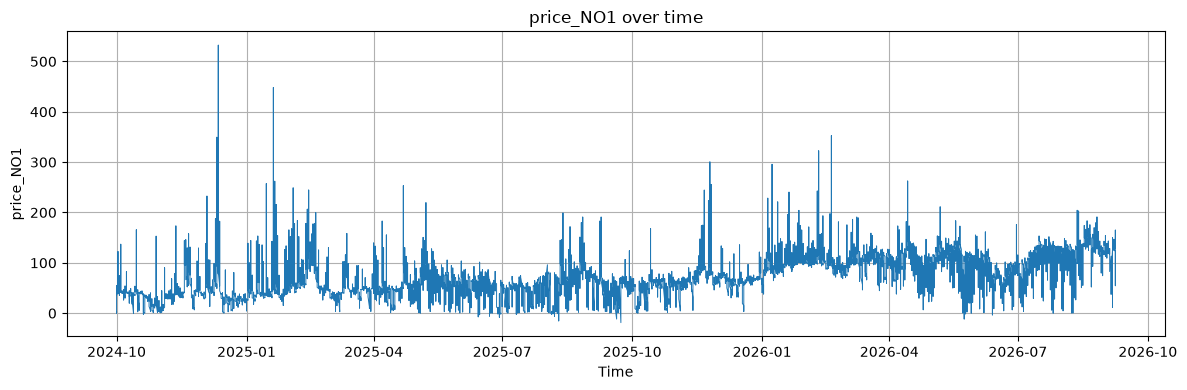

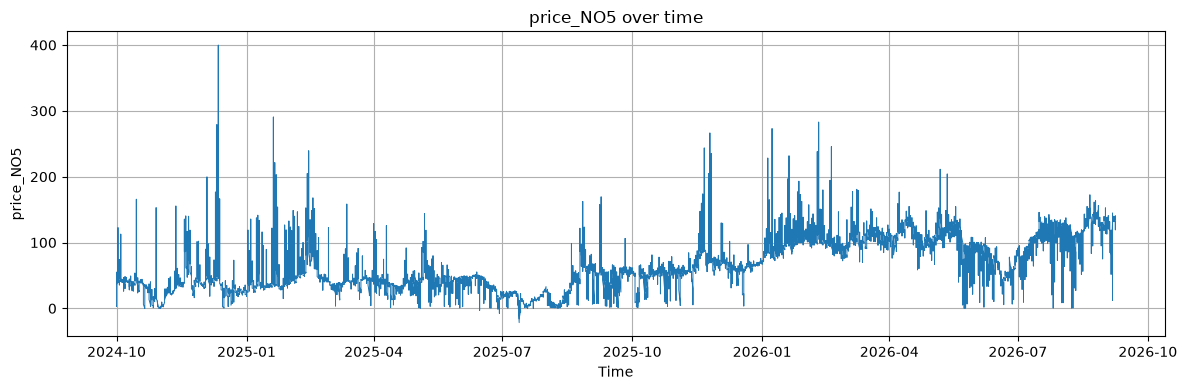

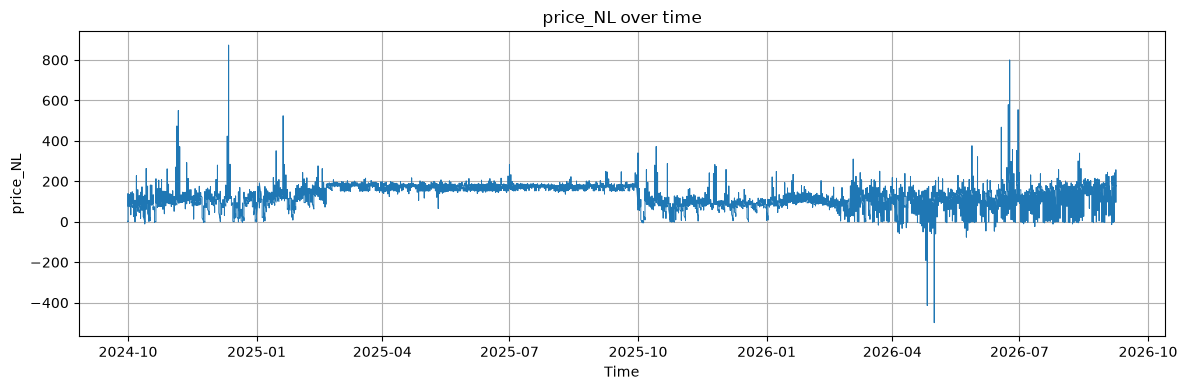

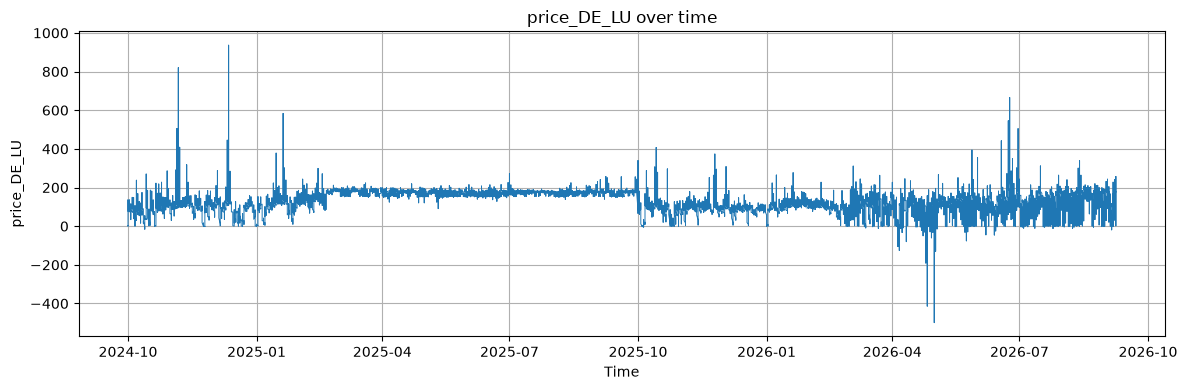

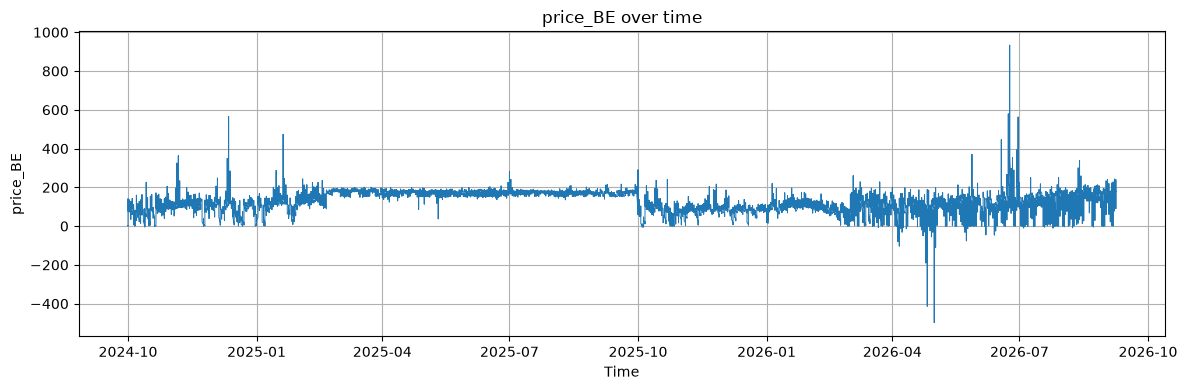

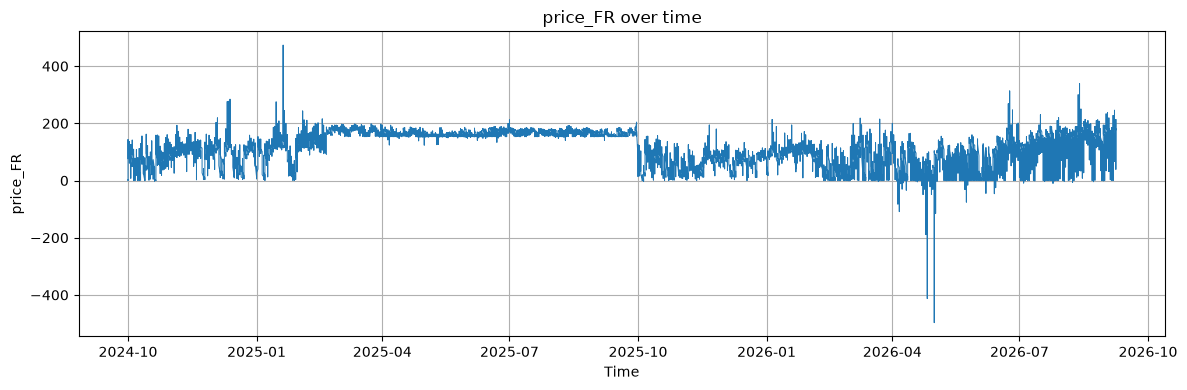

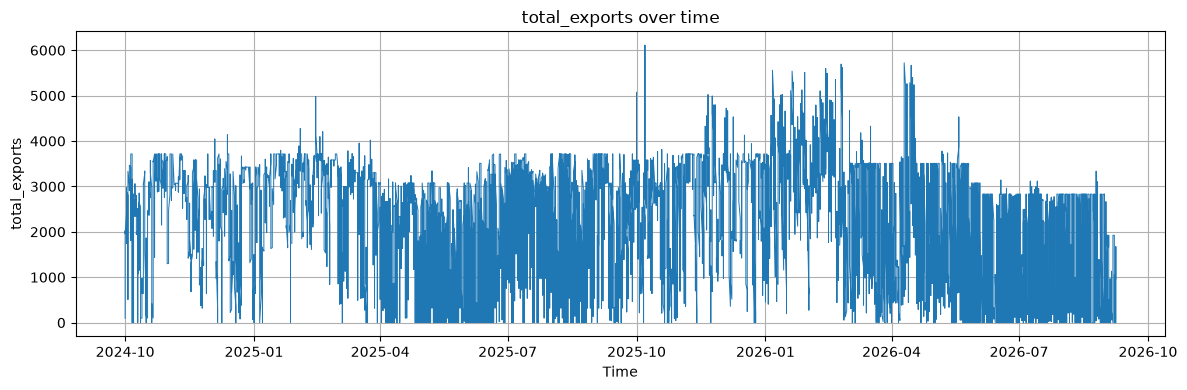

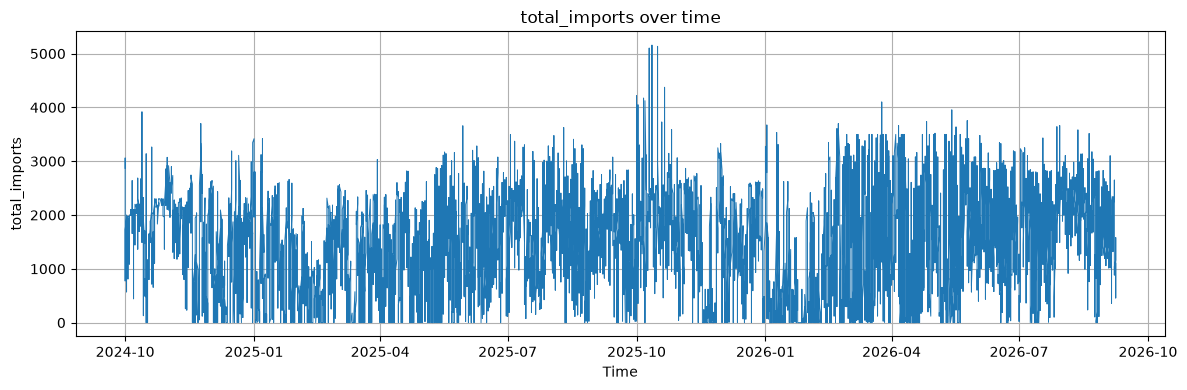

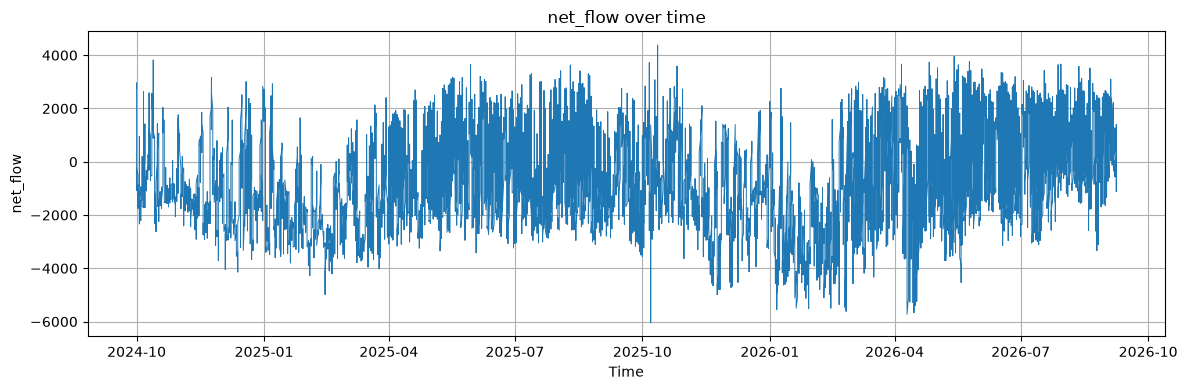

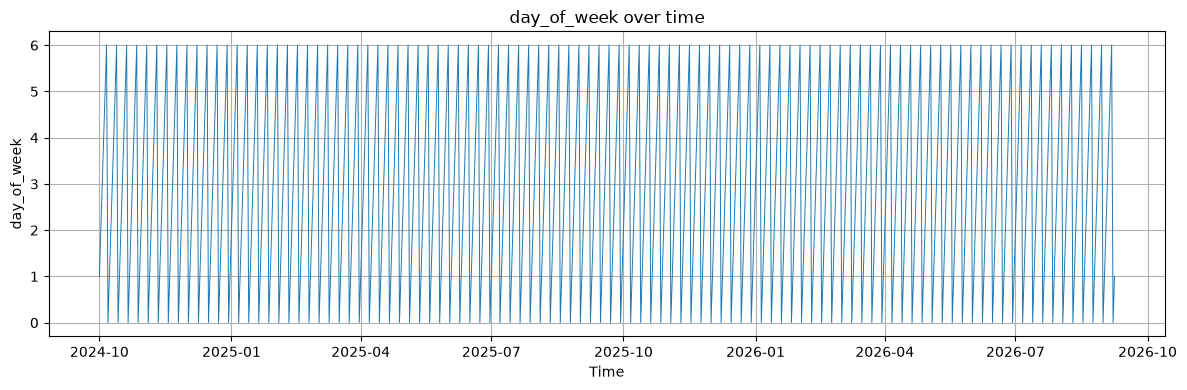

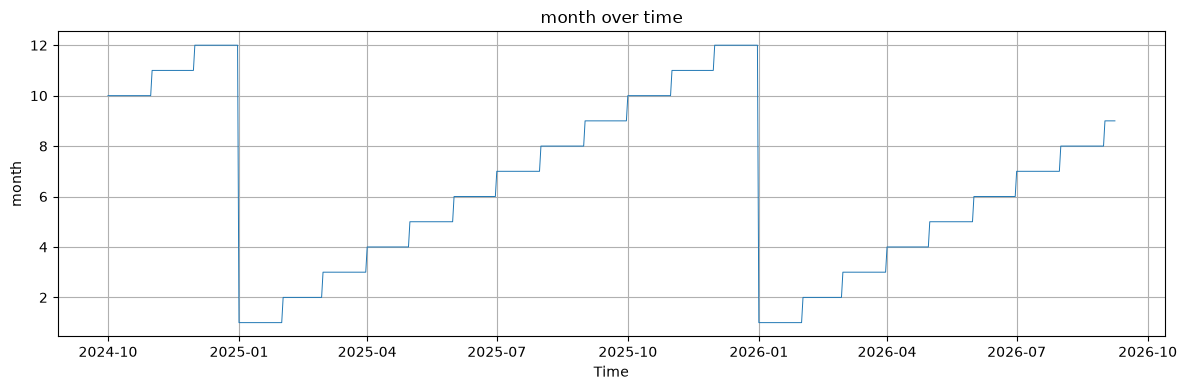

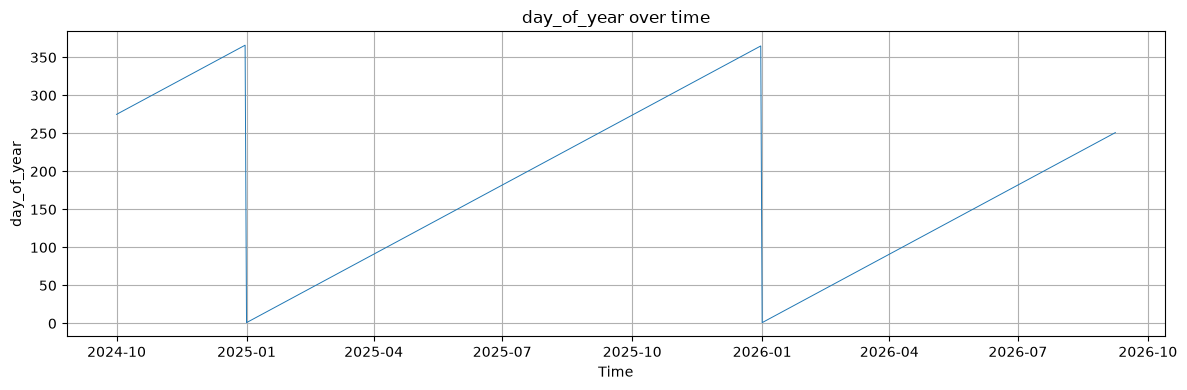

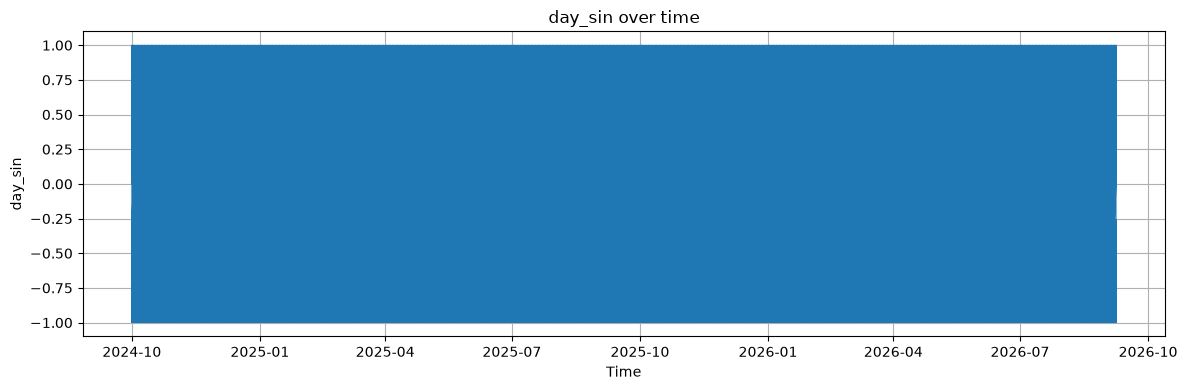

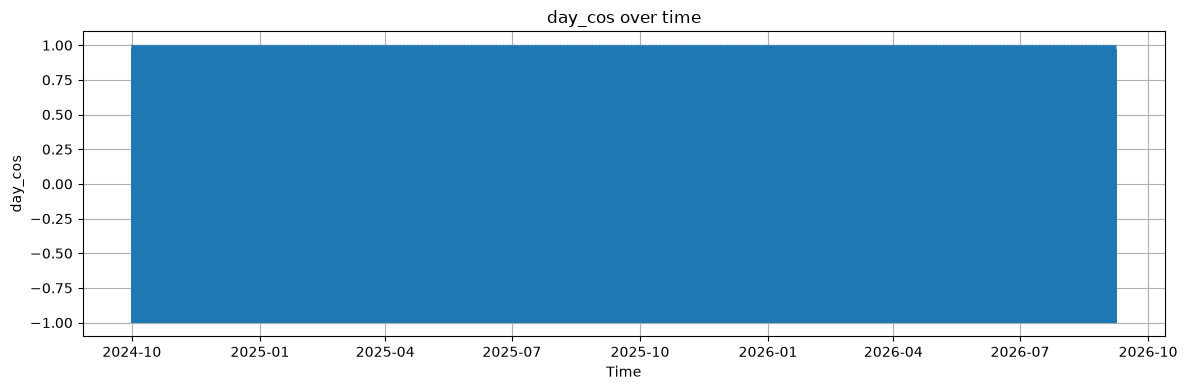

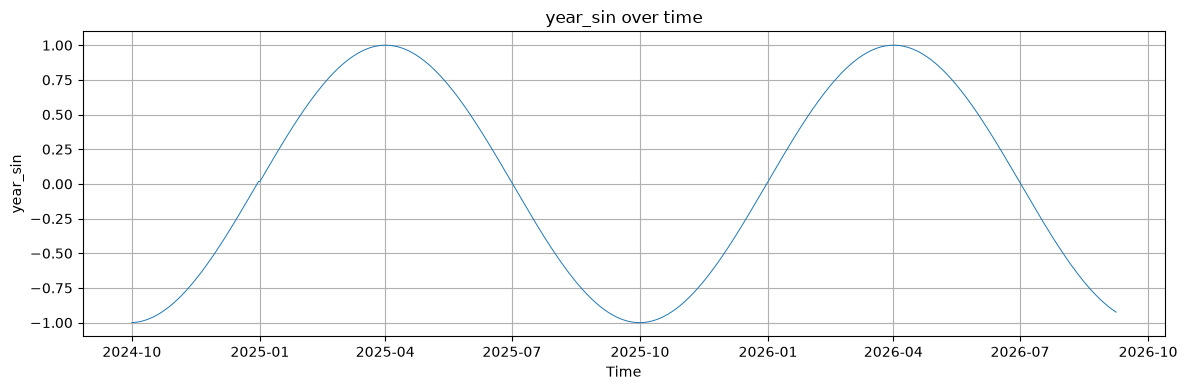

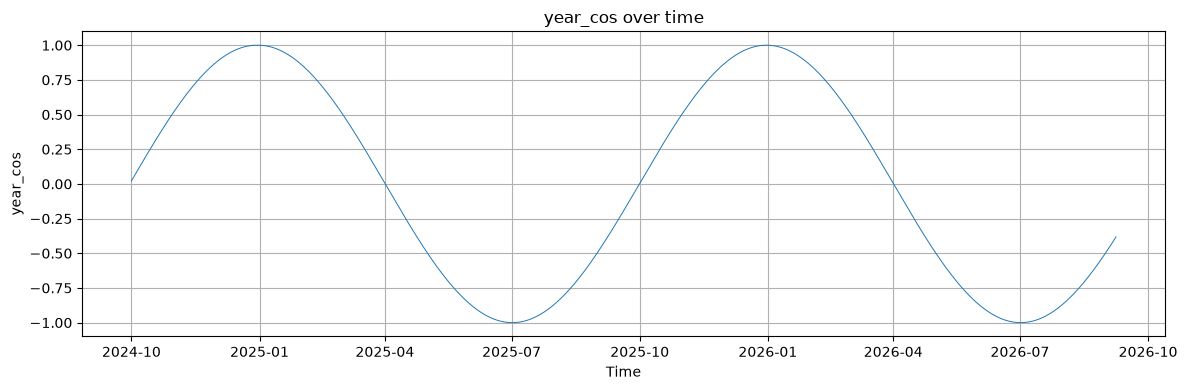

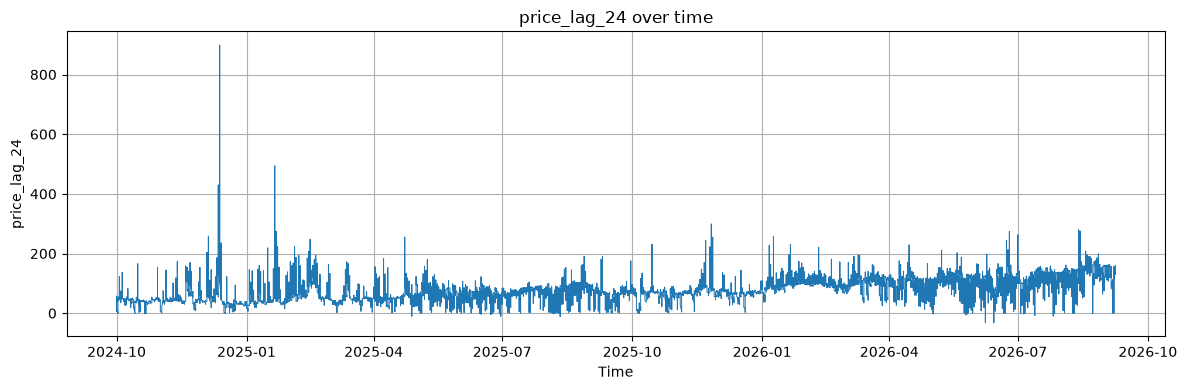

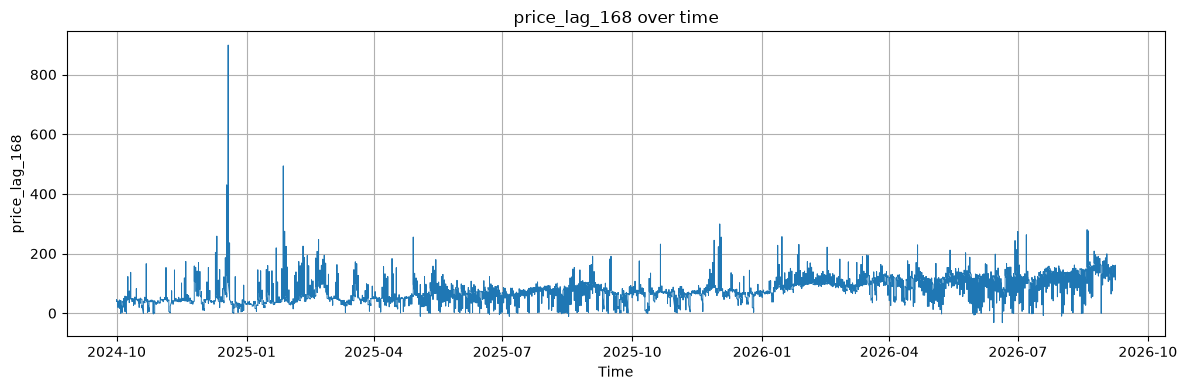

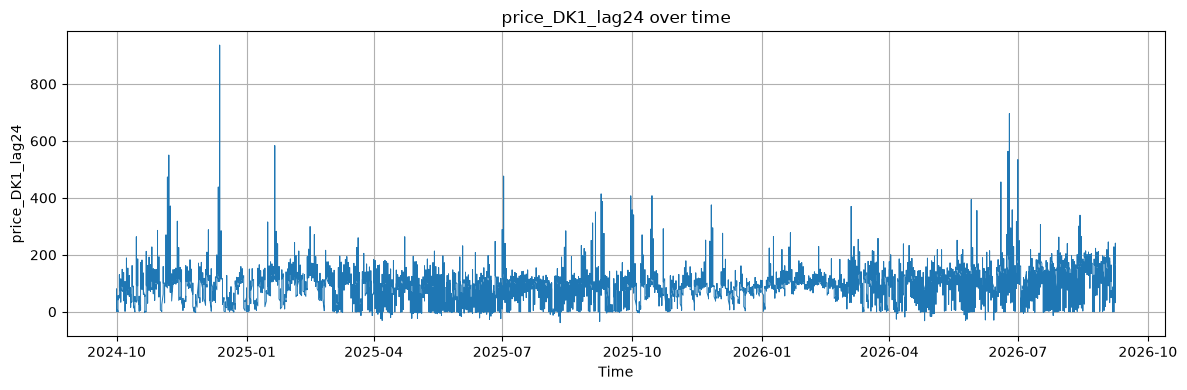

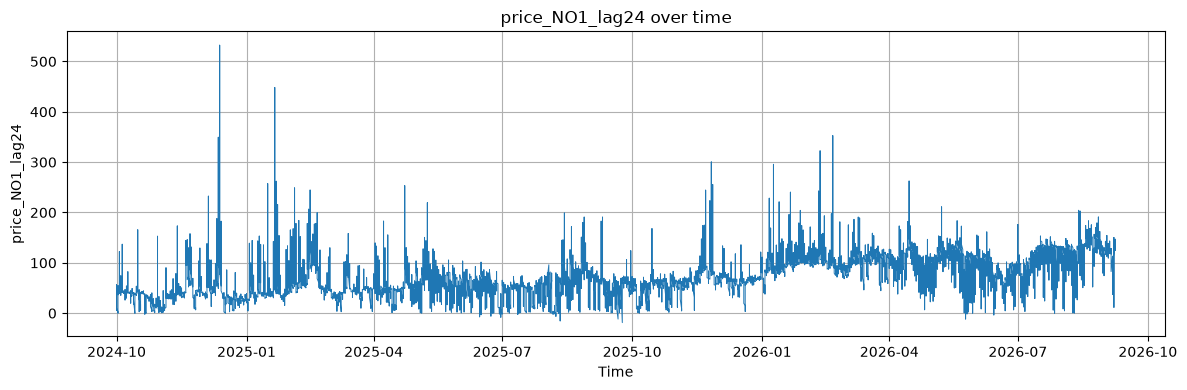

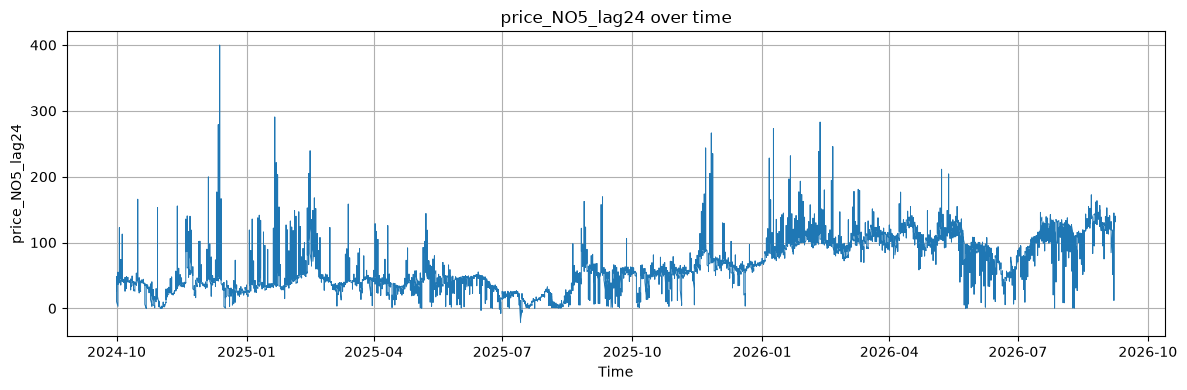

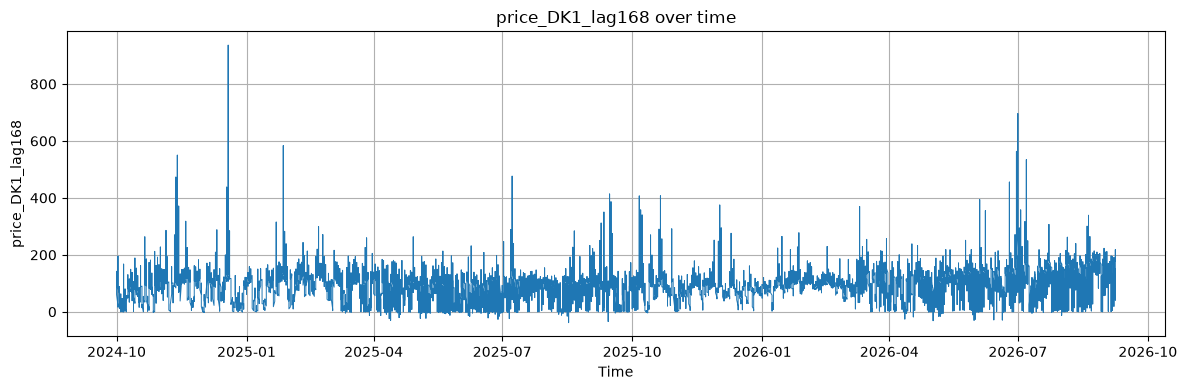

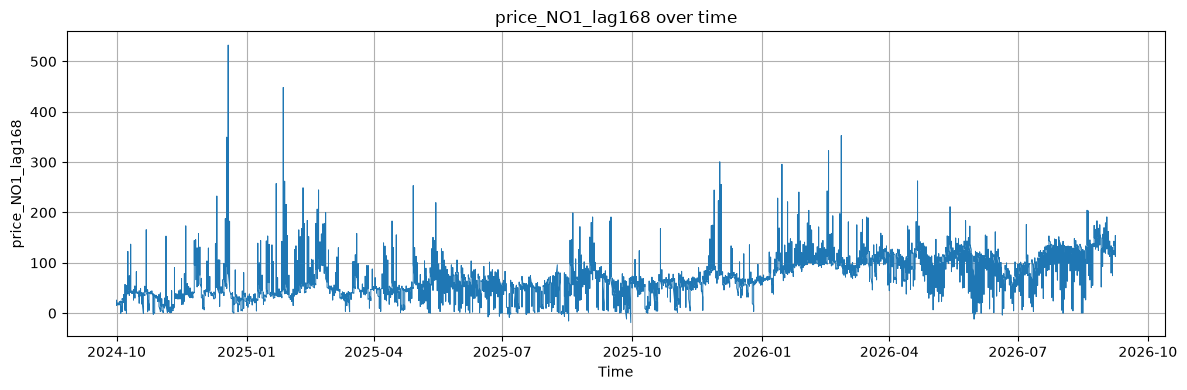

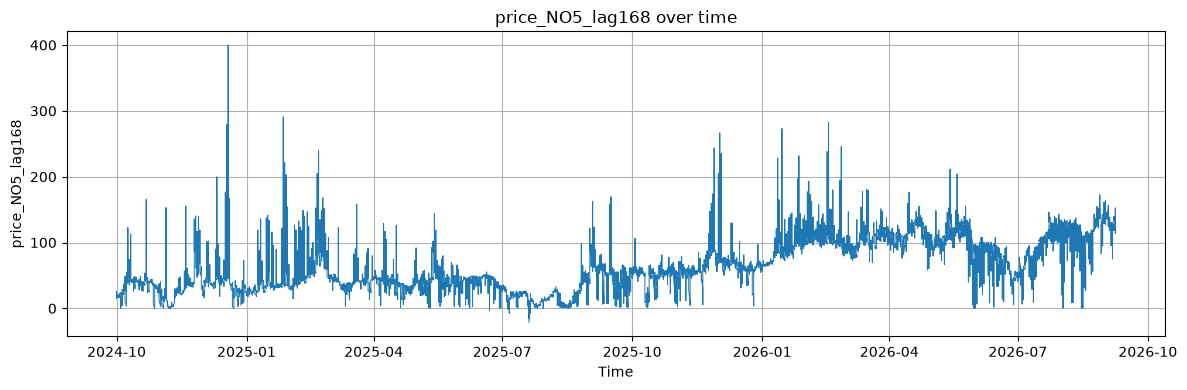

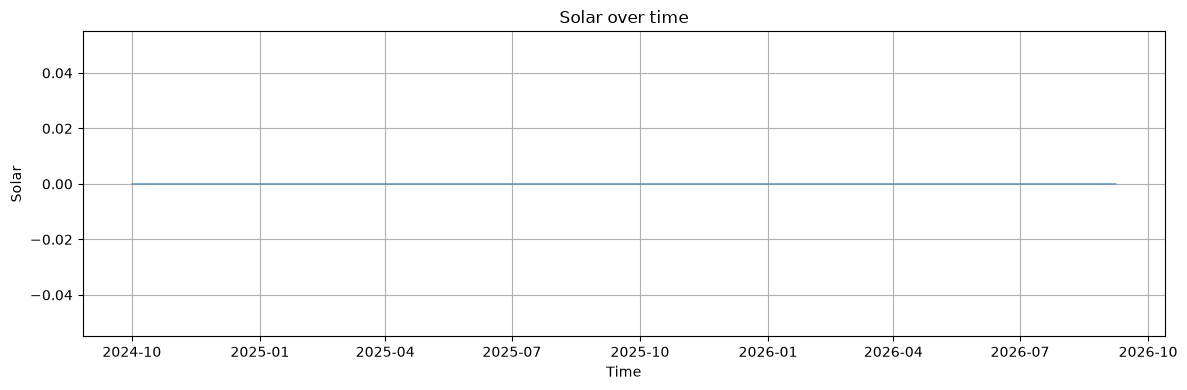

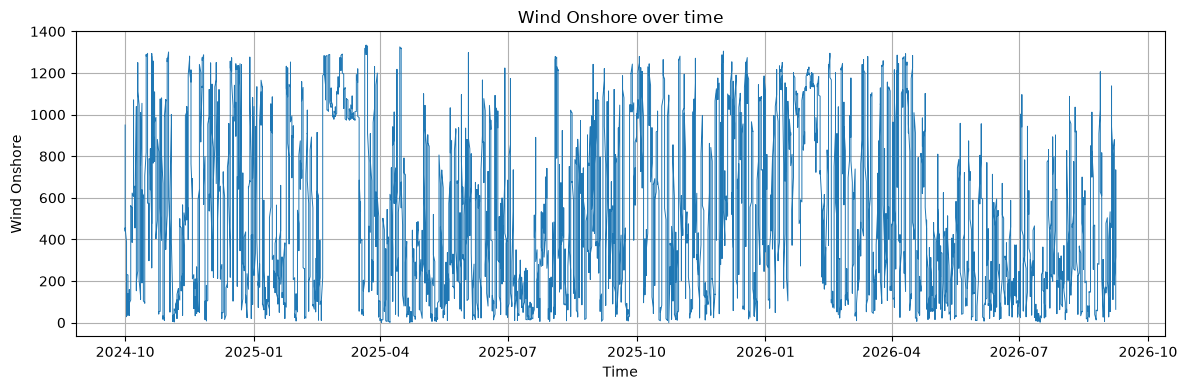

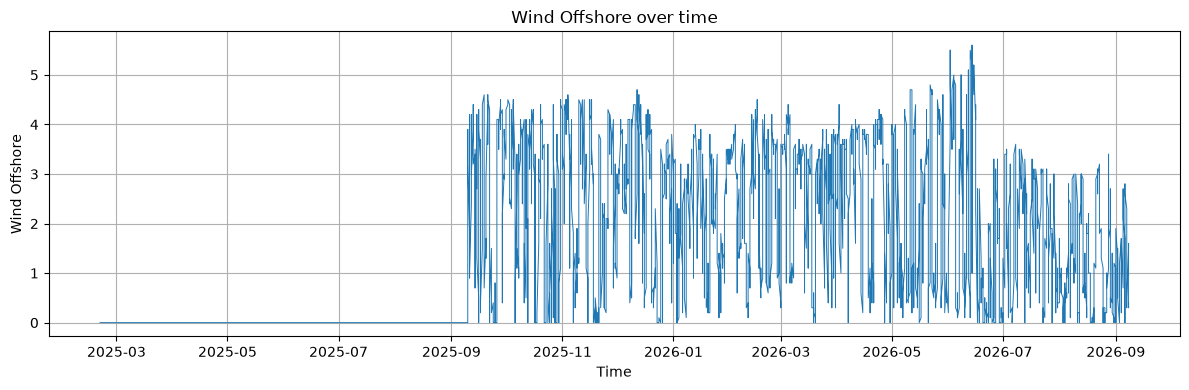

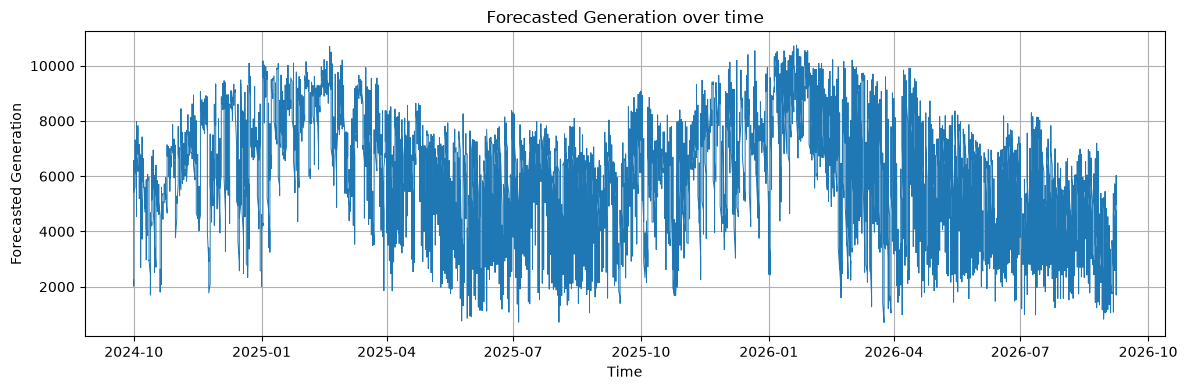

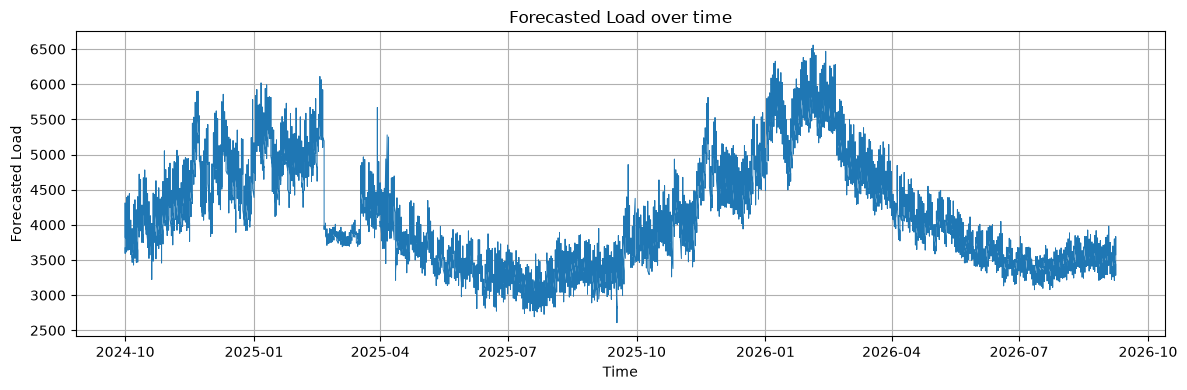

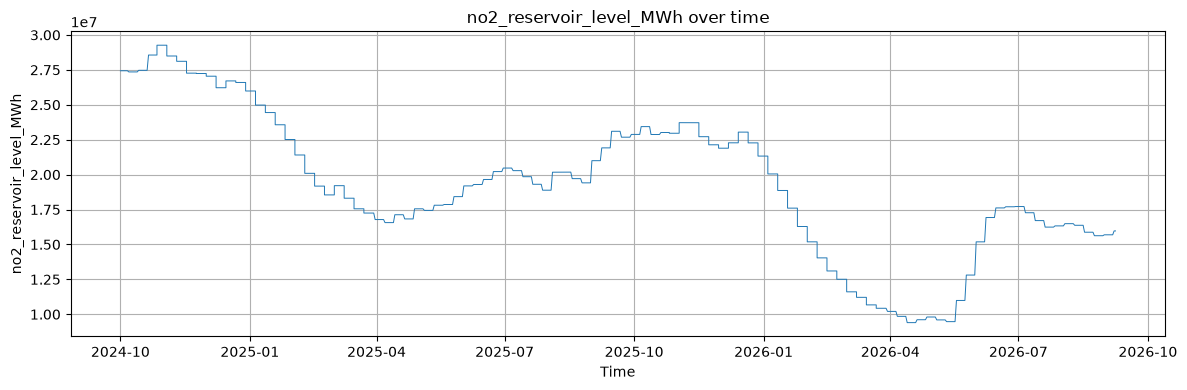

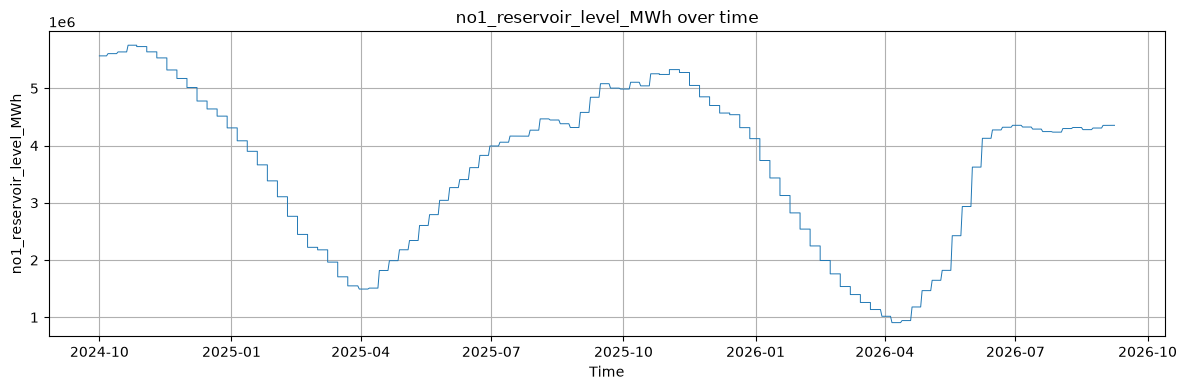

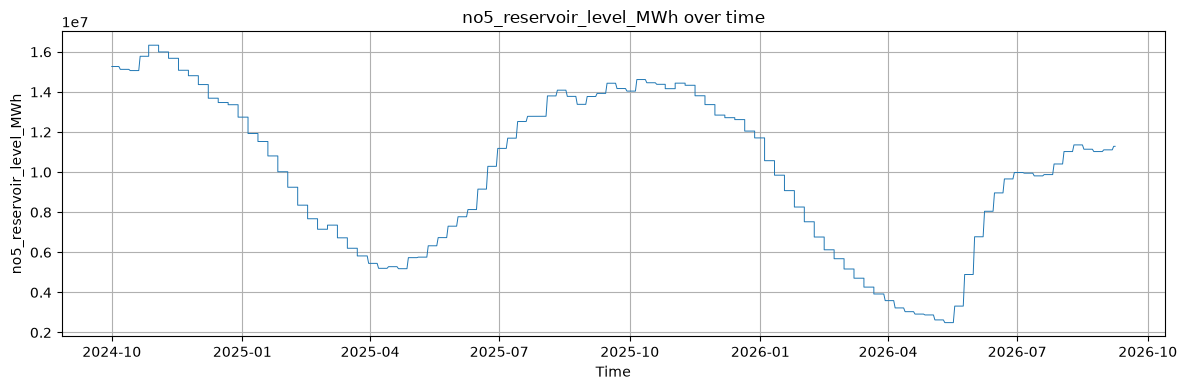

In [24]:
for feature in feature_columns:
    plt.figure(figsize=(12, 4))
    plt.plot(
        data["delivery_day"],
        data[feature],
        linewidth=0.7
    )
    plt.xlabel("Time")
    plt.ylabel(feature)
    plt.title(f"{feature} over time")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Common functions

In [26]:
def evaluate(y_true, y_pred):
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

In [27]:
def plot_results(x_data, test_pred, test_targets, test_pred_label, test_target_label, title, y_label):  
    plt.figure(figsize=(12, 7))
    plt.plot(x_data, test_pred, label=test_pred_label, linewidth=0.7)
    plt.plot(x_data, test_targets, label=test_target_label, linewidth=0.7)
    plt.xlabel("Time")
    plt.ylabel(y_label)
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Testing Models

In [28]:
feature_data = data[feature_columns]
target_data = data['target_price_next_day']

## Random forest regressor

Random forest regressor scores:
  MSE: 874.0832
  RMSE: 29.5649
  R2: 0.5014


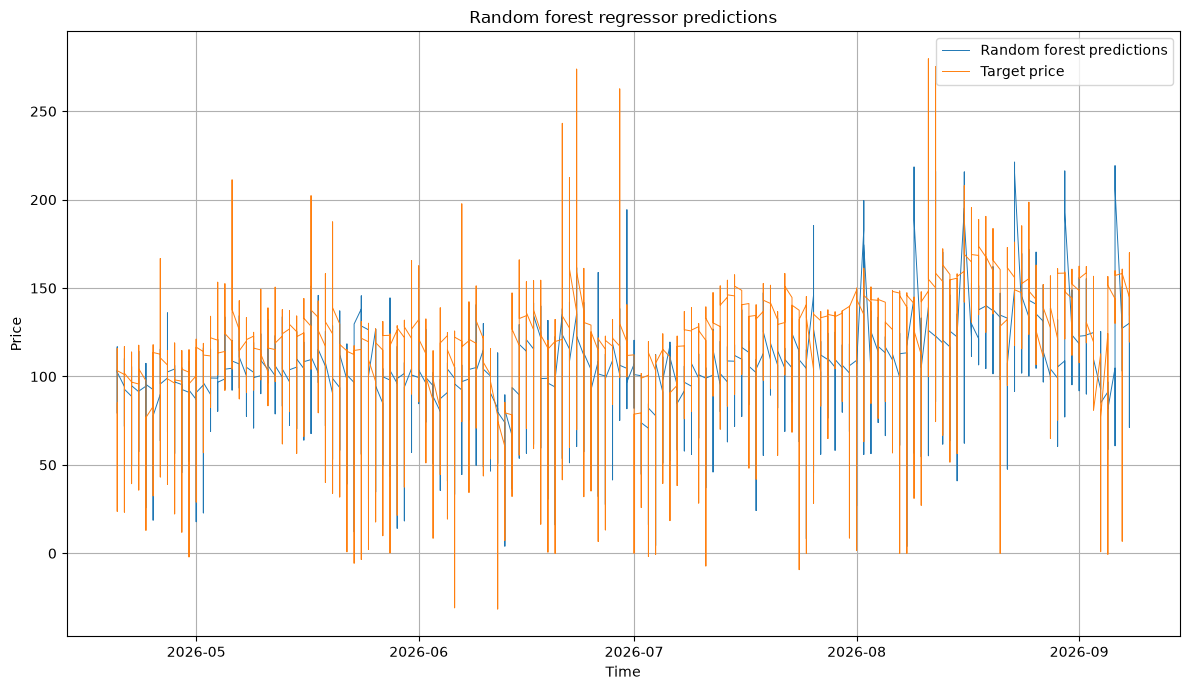

In [29]:
train_end = int(len(feature_data) * 0.8)

train_data = feature_data.iloc[:train_end]
train_targets = target_data.iloc[:train_end]

test_data = feature_data.iloc[train_end:]
test_targets = target_data.iloc[train_end:]


rf_model = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )

rf_model.fit(train_data, train_targets)

rf_test_pred = rf_model.predict(test_data)


rf_test_scores = evaluate(test_targets, rf_test_pred)

print("Random forest regressor scores:")
for name, score in rf_test_scores.items():
    print(f"  {name}: {score:.4f}")

x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=rf_test_pred, 
             test_targets=test_targets, 
             test_pred_label="Random forest predictions", 
             test_target_label="Target price", 
             title="Random forest regressor predictions", 
             y_label="Price")


## Dummy regressor

Dummy regressor scores:
  MSE: 3053.5992
  RMSE: 55.2594
  R2: -0.7419


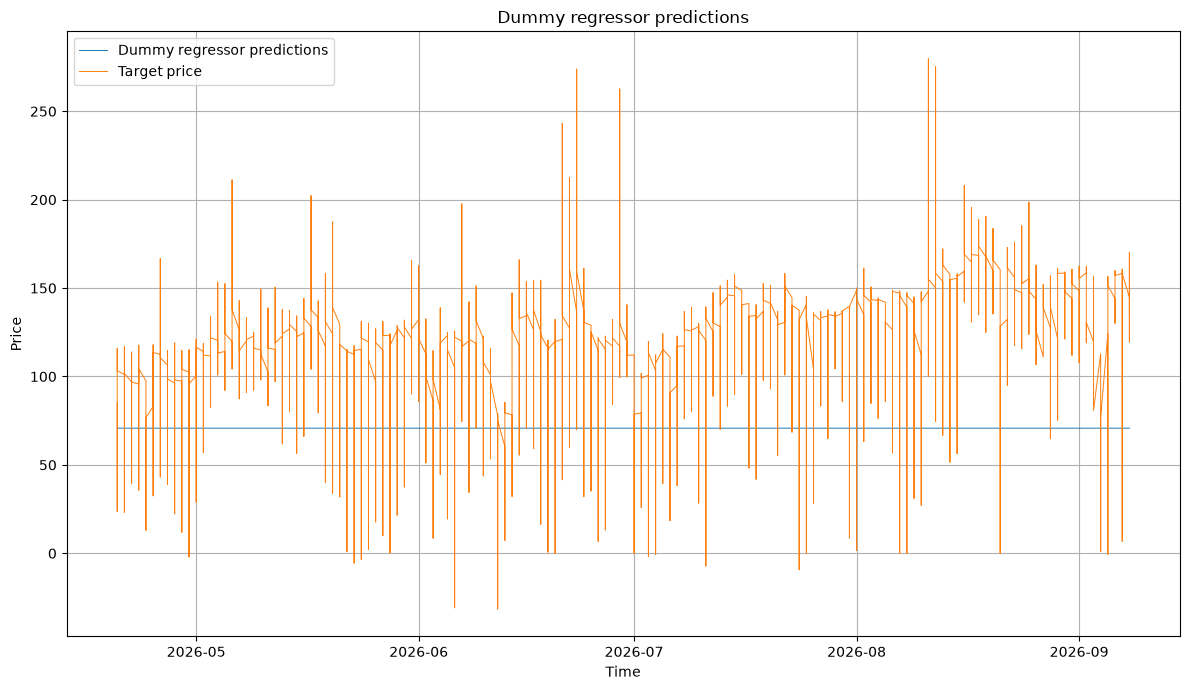

In [30]:
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(train_data, train_targets)

dummy_test_pred = dummy_model.predict(test_data)

dummy_test_scores = evaluate(test_targets, dummy_test_pred)

print("Dummy regressor scores:")
for name, score in dummy_test_scores.items():
    print(f"  {name}: {score:.4f}")


x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=dummy_test_pred, 
             test_targets=test_targets, 
             test_pred_label="Dummy regressor predictions", 
             test_target_label="Target price", 
             title="Dummy regressor predictions", 
             y_label="Price")


# XGBoost Regressor

In [31]:
train_end = int(len(feature_data) * 0.7)
val_end = int(len(feature_data) * 0.85)

train_data = feature_data.iloc[:train_end]
train_targets = target_data.iloc[:train_end]

validation_data = feature_data.iloc[train_end:val_end]
validation_targets = target_data.iloc[train_end:val_end]

test_data = feature_data.iloc[val_end:]
test_targets = target_data.iloc[val_end:]


xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.6,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

xgb_model.fit(
    train_data,
    train_targets,
    eval_set=[(validation_data, validation_targets)],
    verbose=True,
)

xgb_val_pred = xgb_model.predict(validation_data)
xgb_test_pred = xgb_model.predict(test_data)

xgb_val_scores = evaluate(validation_targets, xgb_val_pred)
xgb_test_scores = evaluate(test_targets, xgb_test_pred)

print("XGBoost regressor validation scores:")
for name, score in xgb_val_scores.items():
    print(f"  {name}: {score:.4f}")

print("XGBoost regressor test scores:")
for name, score in xgb_test_scores.items():
    print(f"  {name}: {score:.4f}")


[0]	validation_0-rmse:42.94284
[1]	validation_0-rmse:42.19728
[2]	validation_0-rmse:41.52789
[3]	validation_0-rmse:40.89196
[4]	validation_0-rmse:40.31255
[5]	validation_0-rmse:39.65322
[6]	validation_0-rmse:38.83693
[7]	validation_0-rmse:38.08611
[8]	validation_0-rmse:37.54425
[9]	validation_0-rmse:37.07501
[10]	validation_0-rmse:36.47747
[11]	validation_0-rmse:35.80283
[12]	validation_0-rmse:35.19073
[13]	validation_0-rmse:34.54140
[14]	validation_0-rmse:33.88849
[15]	validation_0-rmse:33.72563
[16]	validation_0-rmse:33.18710
[17]	validation_0-rmse:33.12127
[18]	validation_0-rmse:32.64260
[19]	validation_0-rmse:32.10738
[20]	validation_0-rmse:31.63439
[21]	validation_0-rmse:31.07733
[22]	validation_0-rmse:30.69387
[23]	validation_0-rmse:30.21602
[24]	validation_0-rmse:29.91982
[25]	validation_0-rmse:29.53488
[26]	validation_0-rmse:29.14482
[27]	validation_0-rmse:28.93291
[28]	validation_0-rmse:28.58614
[29]	validation_0-rmse:28.32410
[30]	validation_0-rmse:28.11587
[31]	validation_0-

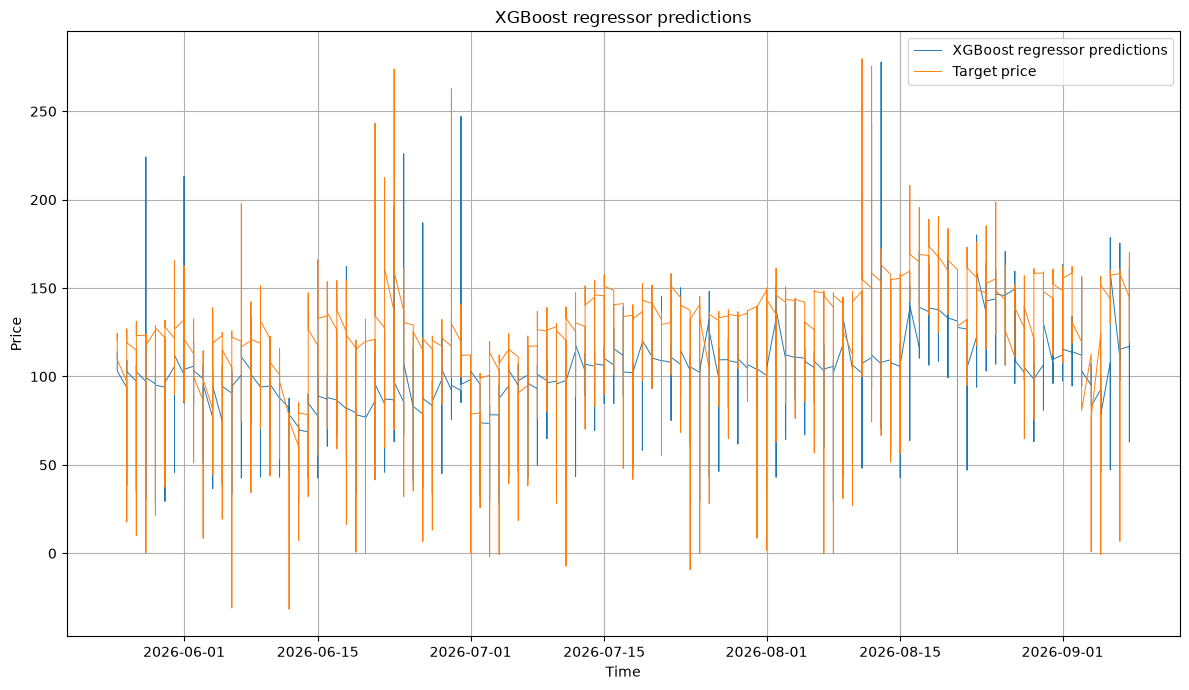

In [32]:
x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=xgb_test_pred, 
             test_targets=test_targets, 
             test_pred_label="XGBoost regressor predictions", 
             test_target_label="Target price", 
             title="XGBoost regressor predictions", 
             y_label="Price")


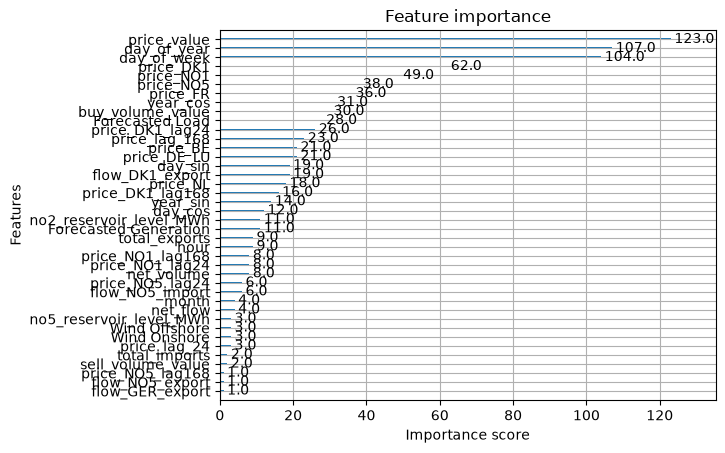

In [33]:
plot_importance(xgb_model)
plt.show()

## Bar chart comparison

In [34]:
results = {"xgb" : xgb_test_scores, "dummy" : dummy_test_scores, "rf" : rf_test_scores}

res_lstm = {'lstm':{'R2': 0.2235, 'RMSE': 36.5655, 'MSE': 1337.0382}}

results= results | res_lstm

In [35]:
metrics = ["RMSE", "MSE", "R2"]
models = list(results.keys())

colors = {
    "xgb": "tab:red",
    "rf": "tab:green",
    "dummy": "tab:blue",
    "lstm": "tab:orange",
}

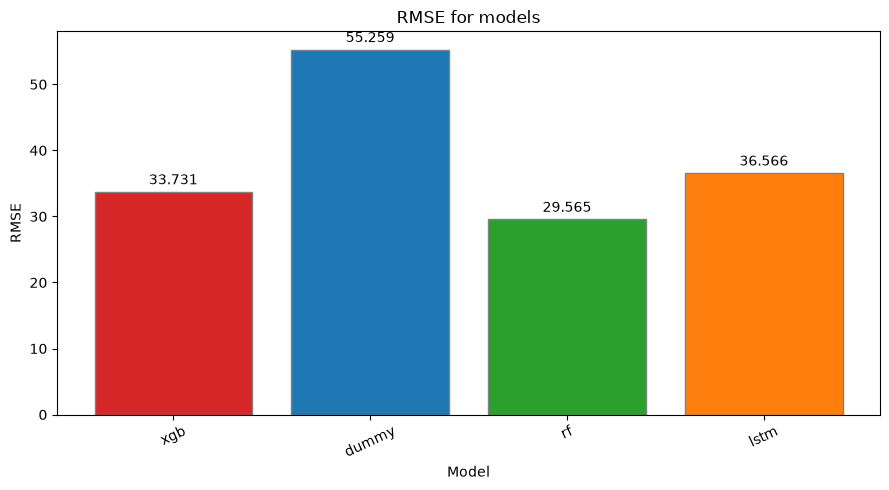

In [36]:
# RMSE
rmse_scores = [results[model]["RMSE"] for model in models]
rmse_colors = [colors[model] for model in models]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, rmse_scores, color=rmse_colors, edgecolor="grey")
ax.set_title("RMSE for models")
ax.set_xlabel("Model")
ax.set_ylabel("RMSE")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()

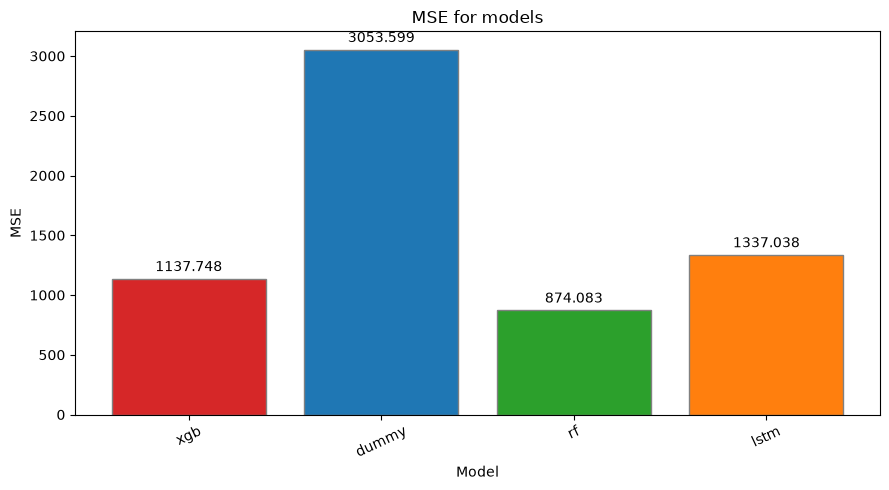

In [37]:
# MSE
mse_scores = [results[model]["MSE"] for model in models]
mse_colors = [colors[model] for model in models]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, mse_scores, color=mse_colors, edgecolor="grey")
ax.set_title("MSE for models")
ax.set_xlabel("Model")
ax.set_ylabel("MSE")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()

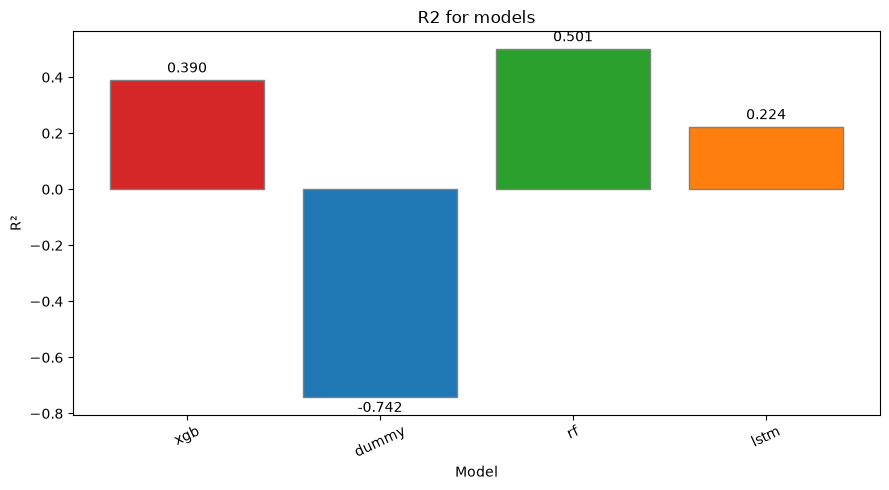

In [38]:
# R2
r2_scores = [results[model]["R2"] for model in models]
r2_colors = [colors[model] for model in models]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, r2_scores, color=r2_colors, edgecolor="grey")
ax.set_title("R2 for models")
ax.set_xlabel("Model")
ax.set_ylabel("R²")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()